# **Ô 1: Khởi tạo môi trường, Đồng bộ Repo 3 tập và Kiểm tra Dữ liệu Module 2**
### Ô 1: Khởi tạo môi trường GPU, Kết nối Google Drive, Đồng bộ Repo 3 tập và Kiểm tra Dữ liệu Module 2
- **Tên công việc:** Thiết lập môi trường làm việc chuẩn trên Google Colab và kiểm kê toàn bộ đầu vào từ Module 1 & Module 2 (bản chia 3 tập mới nhất của nhóm).
- **Mục đích:**
  1. Kiểm tra trạng thái GPU T4 để phục vụ huấn luyện CNN đa tham số.
  2. Kết nối Google Drive và tạo thư mục lưu trữ kết quả mới (`MRI_Colab_Results_3Splits`) tách biệt hoàn toàn với bản 4 tập cũ.
  3. Tải mã nguồn nhánh `main` mới nhất từ GitHub (`haleduoc/MRI`) và bộ dữ liệu BraTS 2020 từ Kaggle.
  4. Đọc và xác minh chính xác tên file, tên cột, số bệnh nhân và số lát cắt theo 3 tập `train / validation / test` trong `results/module2/`.
- **Đầu vào:** Kho GitHub `https://github.com/haleduoc/MRI.git` và dataset Kaggle `awsaf49/brats20-dataset-training-validation`.
- **Đầu ra:** Môi trường sẵn sàng tại `/content/MRI`, đường dẫn dữ liệu Kaggle và báo cáo kiểm tra tính toàn vẹn của 3 tập dữ liệu (không trùng lặp bệnh nhân giữa các tập).

In [1]:
# ==============================================================================
# Ô 1: KHỞI TẠO MÔI TRƯỜNG GPU, KẾT NỐI DRIVE, ĐỒNG BỘ REPO 3 TẬP & KIỂM TRA M2
# ==============================================================================
import os
import glob
import torch
import pandas as pd
import kagglehub
from google.colab import drive

# 1. Kiểm tra phần cứng GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[1/4] Thiết bị đang sử dụng: {device.upper()}")
if device == "cuda":
    print("      Tên GPU:", torch.cuda.get_device_name(0))
else:
    print("      CẢNH BÁO: Chưa bật GPU T4! Hãy vào Runtime -> Change runtime type -> T4 GPU.")

# 2. Kết nối Google Drive và tạo thư mục lưu kết quả bản 3 tập mới
drive.mount("/content/drive")
drive_out = "/content/drive/MyDrive/MRI_Colab_Results_3Splits"
os.makedirs(drive_out, exist_ok=True)
print(f"[2/4] Thư mục lưu kết quả trên Drive: {drive_out}")

# 3. Tải kho mã nguồn nhánh main mới nhất của nhóm
!rm -rf /content/MRI
!git clone -q https://github.com/haleduoc/MRI.git /content/MRI
%cd /content/MRI
print("[3/4] 3 commit gần nhất trên nhánh main:")
!git log -n 3 --oneline

# 4. Tải đường dẫn dataset gốc BraTS 2020 từ Kaggle
kaggle_root = kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation")
print(f"[4/4] Đường dẫn dataset Kaggle: {kaggle_root}")

# 5. Kiểm tra tự động toàn bộ file quy tắc và CSV trong results/module2
print("\n" + "=" * 75)
print("KIỂM TRA ĐẦU VÀO MODULE 2 (BẢN CHIA 3 TẬP TRAIN / VALIDATION / TEST)")
print("=" * 75)

for f in sorted(glob.glob("./results/module2/**/*", recursive=True)):
    if f.endswith(".txt"):
        print(f"\n--- FILE TXT: {f} ---")
        with open(f, encoding="utf-8-sig") as fp:
            print(fp.read().strip())
    elif f.endswith(".csv"):
        df = pd.read_csv(f)
        print(f"\n--- FILE CSV: {f} | Kích thước: {df.shape} ---")
        print("Các cột:", list(df.columns))
        print(df.head(2).to_string(index=False))
        for col in ["split", "tap", "label"]:
            if col in df.columns:
                print(f"Phân bố [{col}]: {df[col].value_counts(dropna=False).to_dict()}")
        if "patient_id" in df.columns and "split" in df.columns:
            print("Số bệnh nhân theo split:", df.groupby("split")["patient_id"].nunique().to_dict())
            overlap = int((df.groupby("patient_id")["split"].nunique() > 1).sum())
            print("Số bệnh nhân trùng chéo giữa các tập (bắt buộc = 0):", overlap)

[1/4] Thiết bị đang sử dụng: CUDA
      Tên GPU: Tesla T4
Mounted at /content/drive
[2/4] Thư mục lưu kết quả trên Drive: /content/drive/MyDrive/MRI_Colab_Results_3Splits
/content/MRI
[3/4] 3 commit gần nhất trên nhánh main:
7b1e422 (HEAD -> main, origin/main, origin/HEAD) Features/TSV
d7525cb Prepare M1 M2 datasets and split
823e14d Merge pull request #6 from haleduoc/feature/interface
Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.
[4/4] Đường dẫn dataset Kaggle: /kaggle/input/brats20-dataset-training-validation

KIỂM TRA ĐẦU VÀO MODULE 2 (BẢN CHIA 3 TẬP TRAIN / VALIDATION / TEST)

--- FILE CSV: ./results/module2/Chi_muc_lat/chi_muc_lat.csv | Kích thước: (57040, 6) ---
Các cột: ['patient_id', 'split', 'slice_index', 'label', 'flair_path', 'wt_path']
          patient_id split  slice_index  label                                                                                                                       flair_path                     

# **Ô 2: Module 3 (Phần 1) — Khảo sát 5 lát cắt đại diện từ tập train & Đánh giá các bộ lọc**
### Ô 2: Module 3 (Phần 1) — Khảo sát 5 lát cắt đại diện trên tập `train` và Đánh giá định lượng các bộ lọc
- **Tên công việc:** Trích xuất 5 lát cắt đại diện hoàn toàn từ tập `train` và chạy thực nghiệm đối chứng các bước tiền xử lý ảnh MRI FLAIR 2D.
- **Mục đích:**
  1. Kiểm chứng quy tắc **lọc lát cắt rỗng** dựa trên diện tích tiền cảnh não ($A_{\text{brain}} \ge 500\text{ px}$).
  2. Khảo sát và đo lường định lượng (CNR, nhiễu $\sigma_{\text{Lap}}$, độ nét biên $|\nabla I|$, Entropy, % mô lành sáng quá ngưỡng $>0.75$) qua từng bước:
     - **Bước 1:** Chuẩn hóa sáng `Min-Max` vs `Percentile [P1, P99]` vs `[P5, P90]`.
     - **Bước 2:** Khử nhiễu `Bilateral Filter` (Thấp $\sigma_r=5$ / Chuẩn $\sigma_r=25$ / Cao $\sigma_r=150$) và đối chứng `Non-Local Means`.
     - **Bước 3:** Tăng tương phản cục bộ `CLAHE` (Thấp `0.5` / Chuẩn `2.0` / Cao `8.0`).
     - **Bước 4:** Cắt khung `ROI` cố định & đối chứng nội suy ảnh (`Bilinear`) vs mặt nạ WT (`Nearest-Neighbor`).
  3. Làm rõ cơ sở thực nghiệm cho góp ý của giảng viên: mỗi lát ảnh phù hợp với các đặc trưng bộ lọc khác nhau (lọc Bilateral làm mịn nền tốt, trong khi CLAHE làm nổi bật biên ở các ca u nhỏ/bờ mờ) $\rightarrow$ tiền đề cho việc **giữ lại nhiều phiên bản bộ lọc để tăng cường dữ liệu (Multi-Filter Augmentation)** ở Module 4.
- **Đầu vào:** File chỉ mục lát từ `results/module2/Chi_muc_lat/` và dữ liệu NIfTI 3D chuẩn RAS (Module 1 / Kaggle).
- **Đầu ra:** 5 hình trực quan hóa độ phân giải cao (`300 dpi`) và file tổng hợp chỉ số định lượng lưu tại `MRI_Colab_Results_3Splits/module3_5samples/`.

Đã nạp chỉ mục lát: ./results/module2/Chi_muc_lat/chi_muc_lat.csv (57040 dòng | cột lát: 'slice_index')

=== BƯỚC 0 & 1A: THÔNG SỐ GỐC & LỌC LÁT RỖNG (5 MẪU TẬP TRAIN) ===
  Mẫu           Patient_ID  z Split  Label  A_brain  WT_px     Trạng thái lọc  I_max    P1   P99  TB_Lành  TB_U
Mẫu 1 BraTS20_Training_001 78 train      1    17424   4453            GIỮ LẠI  432.0  43.0 383.0    148.3 296.2
Mẫu 2 BraTS20_Training_002 50 train      1    16379   2019            GIỮ LẠI 1091.0 101.0 720.2    312.1 555.2
Mẫu 3 BraTS20_Training_003 85 train      1    15815    748            GIỮ LẠI  553.0  68.0 493.0    307.1 462.6
Mẫu 4 BraTS20_Training_005 75 train      0    17154      0            GIỮ LẠI  670.0  35.0 304.5    152.6   0.0
Mẫu 5 BraTS20_Training_001  2 train      0        0      0 LOẠI BỎ (Lát rỗng)    0.0   0.0   0.0      0.0   0.0


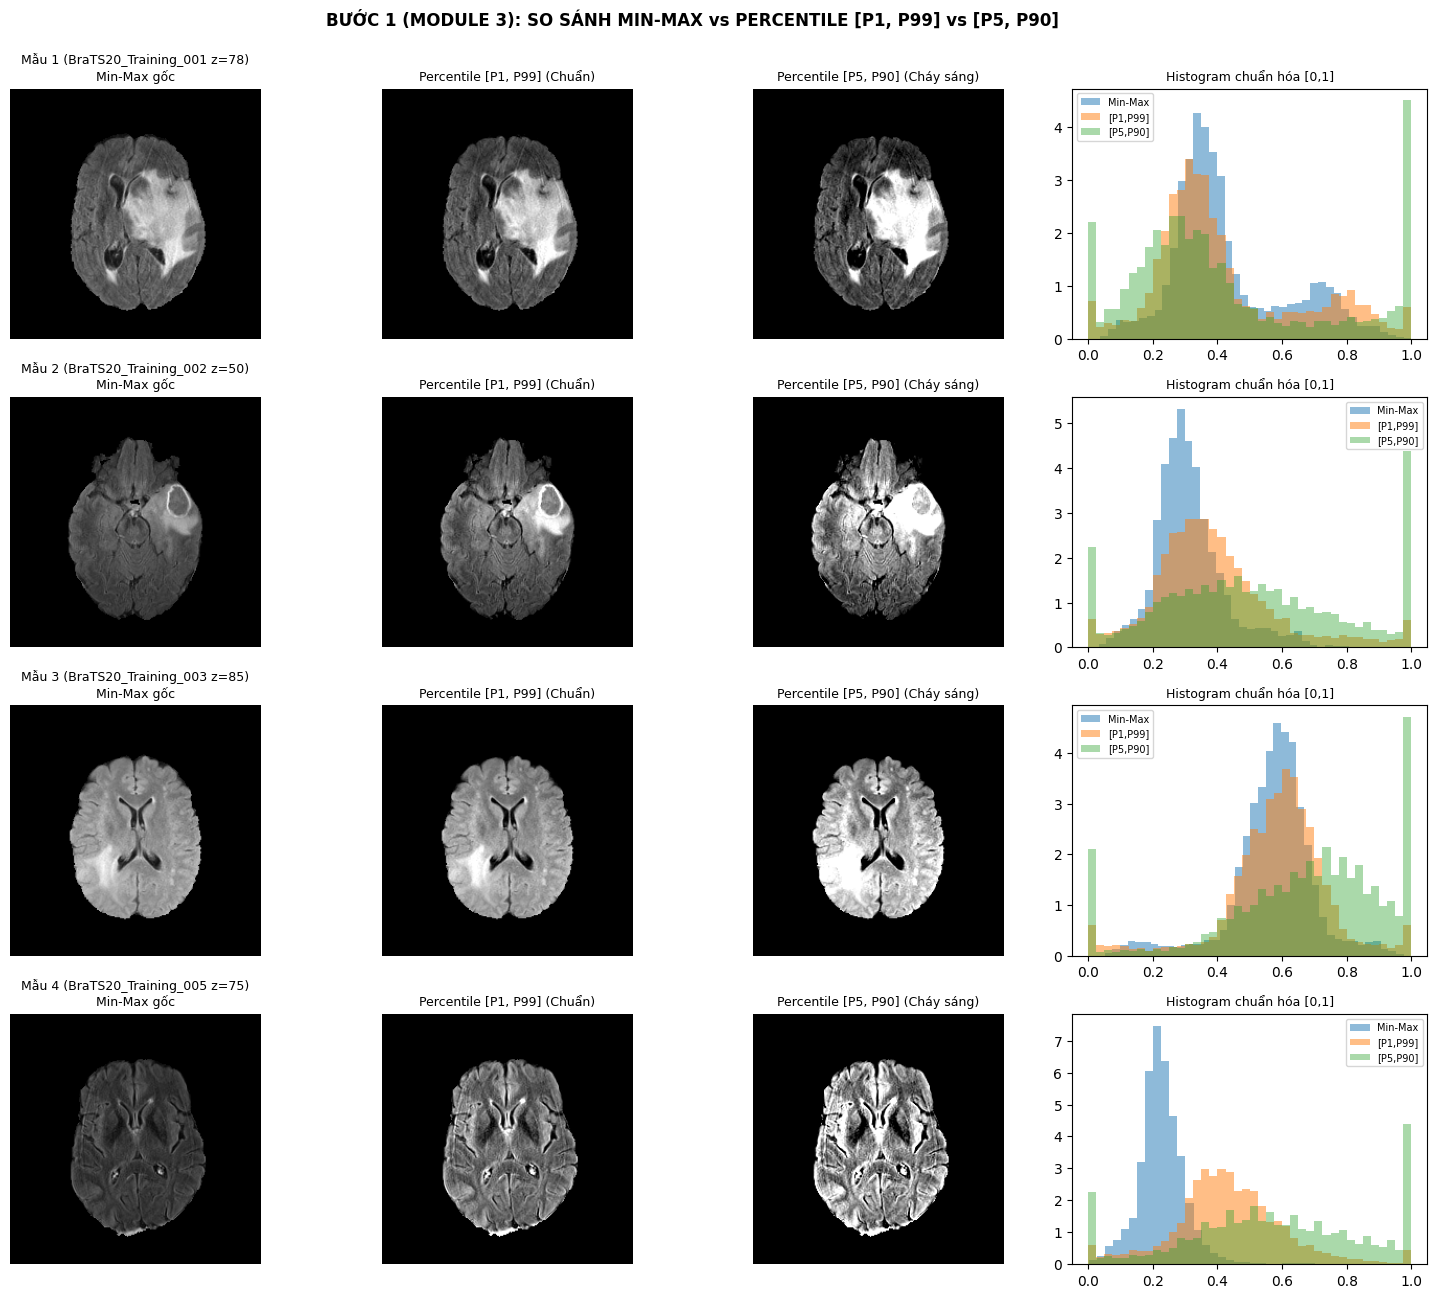


=== BƯỚC 1B: CHỈ SỐ CHUẨN HÓA CƯỜNG ĐỘ ===
  Mẫu       Cấu hình    mu0    mu1  Delta_I  sigma0   CNR  %U_cháy
Mẫu 1        Min-Max 0.3434 0.6857   0.3424  0.0909 3.766     0.02
Mẫu 1 [P1,P99] Chuẩn 0.3102 0.7433   0.4331  0.1145 3.782     4.04
Mẫu 1   [P5,P90] Hẹp 0.2739 0.8690   0.5951  0.1527 3.897    38.09
Mẫu 2        Min-Max 0.2861 0.5089   0.2228  0.0769 2.895     0.05
Mẫu 2 [P1,P99] Chuẩn 0.3413 0.7230   0.3818  0.1341 2.847     7.83
Mẫu 2   [P5,P90] Hẹp 0.4487 0.9427   0.4940  0.2457 2.011    66.02
Mẫu 3        Min-Max 0.5553 0.8365   0.2812  0.1201 2.342     0.13
Mẫu 3 [P1,P99] Chuẩn 0.5628 0.9211   0.3582  0.1550 2.311    21.93
Mẫu 3   [P5,P90] Hẹp 0.6558 0.9997   0.3439  0.2491 1.381    99.47
Mẫu 4        Min-Max 0.2277 0.0000   0.0000  0.0749 0.000     0.00
Mẫu 4 [P1,P99] Chuẩn 0.4338 0.0000   0.0000  0.1714 0.000     0.00
Mẫu 4   [P5,P90] Hẹp 0.5717 0.0000   0.0000  0.2752 0.000     0.00


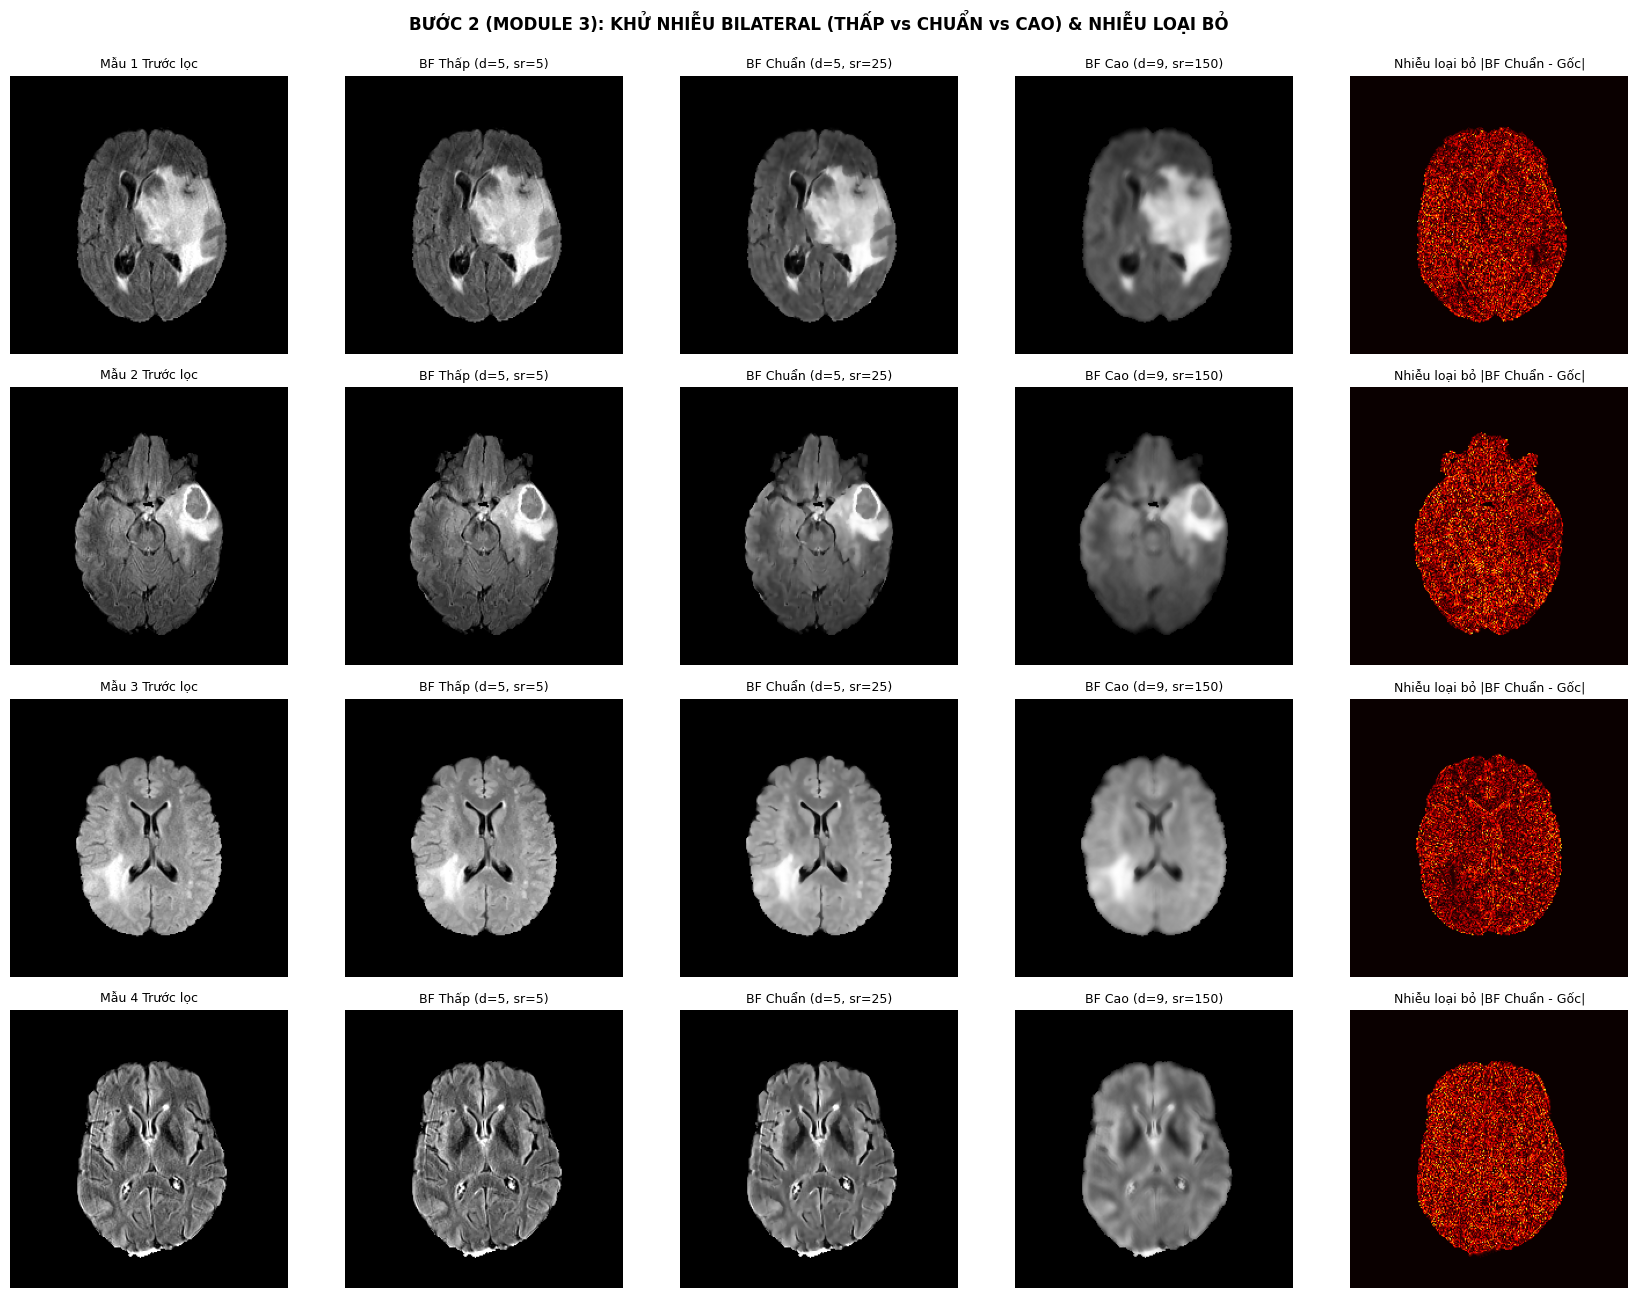


=== BƯỚC 2: CHỈ SỐ KHỬ NHIỄU BILATERAL & NLM ===
  Mẫu         Cấu hình  sigma_Lap  sigma0  |grad_I|   CNR  Time_ms
Mẫu 1         Chưa lọc     0.1700  0.1145    0.8876 3.782     0.00
Mẫu 1   BF Thấp (sr=5)     0.1635  0.1134    0.8834 3.818    15.24
Mẫu 1 BF Chuẩn (sr=25)     0.1246  0.1059    0.8231 4.071     1.10
Mẫu 1  BF Cao (sr=150)     0.0433  0.0876    0.5029 4.786    11.31
Mẫu 1       NLM (h=10)     0.1347  0.1077    0.8701 4.030    73.97
Mẫu 2         Chưa lọc     0.1943  0.1341    0.7969 2.847     0.01
Mẫu 2   BF Thấp (sr=5)     0.1882  0.1332    0.7892 2.867     0.96
Mẫu 2 BF Chuẩn (sr=25)     0.1424  0.1265    0.7299 3.003     0.94
Mẫu 2  BF Cao (sr=150)     0.0448  0.1079    0.4346 3.399     5.56
Mẫu 2       NLM (h=10)     0.1580  0.1290    0.7558 2.955    72.31
Mẫu 3         Chưa lọc     0.1737  0.1550    0.5691 2.311     0.00
Mẫu 3   BF Thấp (sr=5)     0.1691  0.1543    0.5624 2.323     1.02
Mẫu 3 BF Chuẩn (sr=25)     0.1554  0.1501    0.5206 2.361     1.05
Mẫu 3  BF Ca

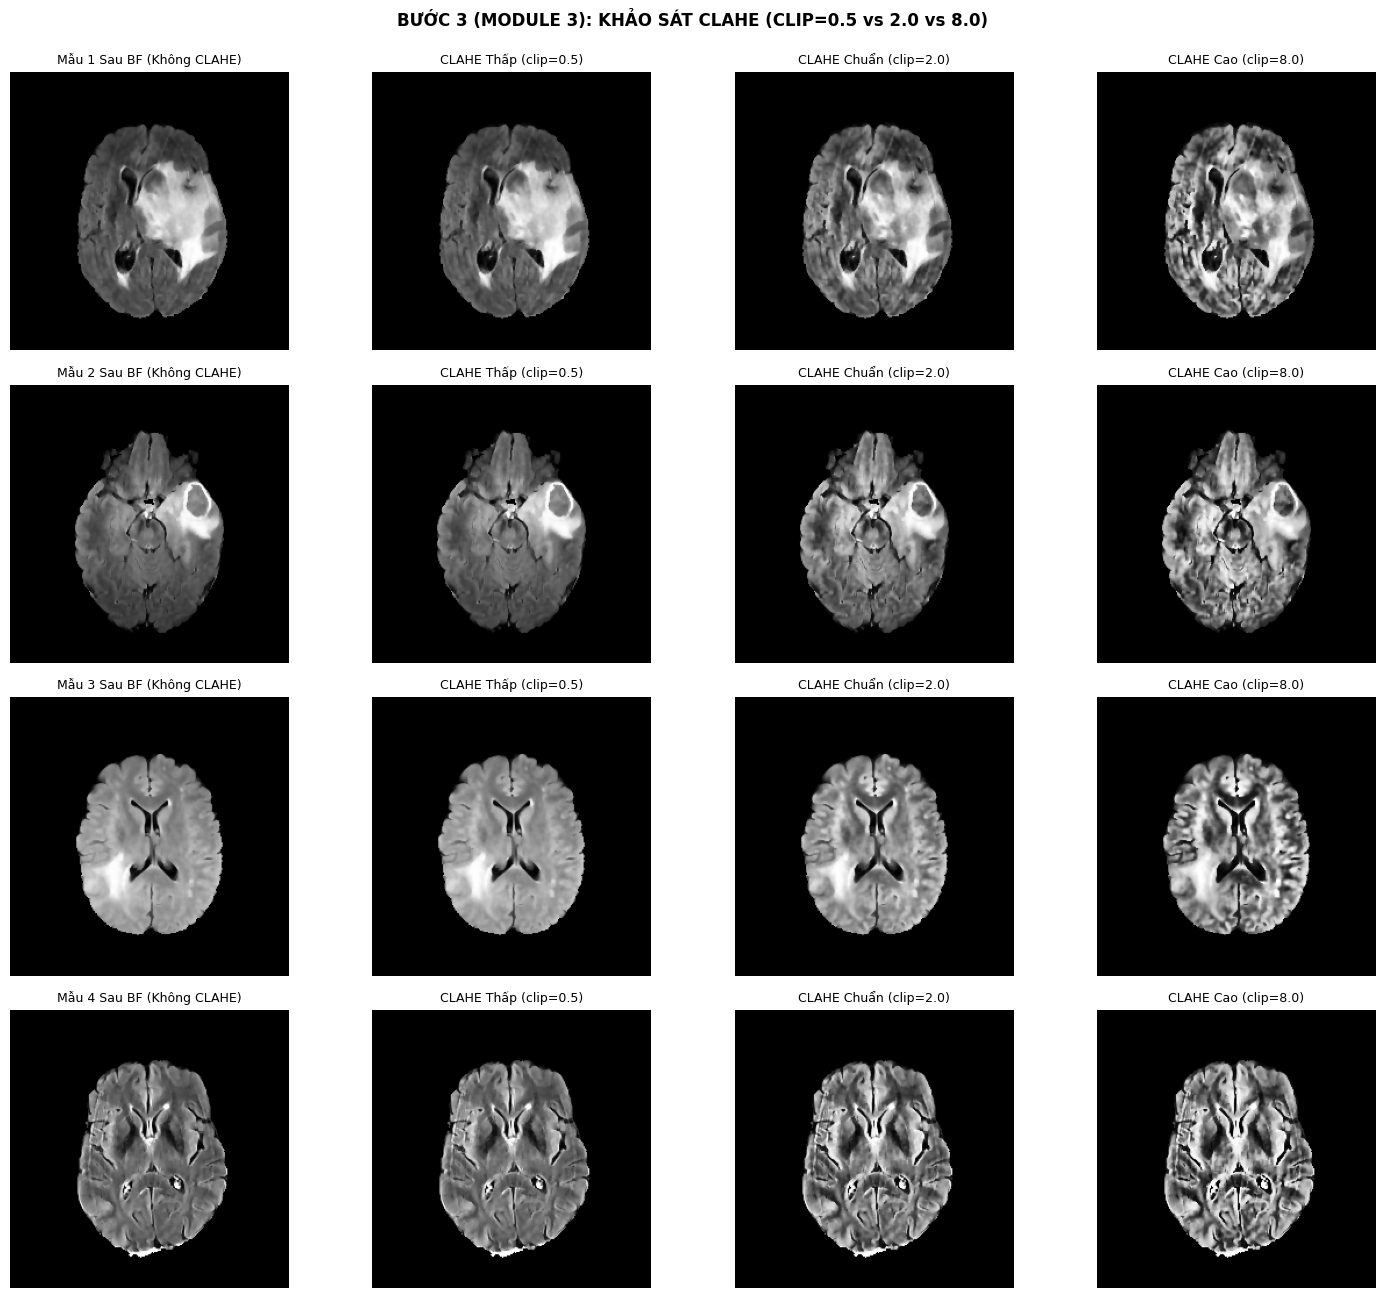


=== BƯỚC 3: CHỈ SỐ CLAHE ===
  Mẫu    Cấu hình  Delta_I  sigma0  |grad_I|  Entropy  %Lành>0.75
Mẫu 1 Trước CLAHE   0.4313  0.1059    0.8231    7.380        0.43
Mẫu 1   CLAHE 0.5   0.4251  0.1127    0.8747    7.444        0.53
Mẫu 1   CLAHE 2.0   0.3360  0.1549    0.9022    7.710        1.34
Mẫu 1   CLAHE 8.0   0.2361  0.2224    0.8777    7.881        8.90
Mẫu 2 Trước CLAHE   0.3799  0.1265    0.7299    7.333        0.46
Mẫu 2   CLAHE 0.5   0.3707  0.1337    0.7706    7.369        0.68
Mẫu 2   CLAHE 2.0   0.3055  0.1783    0.9095    7.681        3.65
Mẫu 2   CLAHE 8.0   0.2550  0.2296    0.9613    7.877       11.78
Mẫu 3 Trước CLAHE   0.3545  0.1501    0.5206    7.090        2.95
Mẫu 3   CLAHE 0.5   0.3463  0.1518    0.5369    7.099        4.21
Mẫu 3   CLAHE 2.0   0.3444  0.1763    0.6398    7.497        9.35
Mẫu 3   CLAHE 8.0   0.3775  0.2380    0.6659    7.899       17.85
Mẫu 4 Trước CLAHE   0.0000  0.1613    0.0000    7.249        3.28
Mẫu 4   CLAHE 0.5   0.0000  0.1718    0.0000  

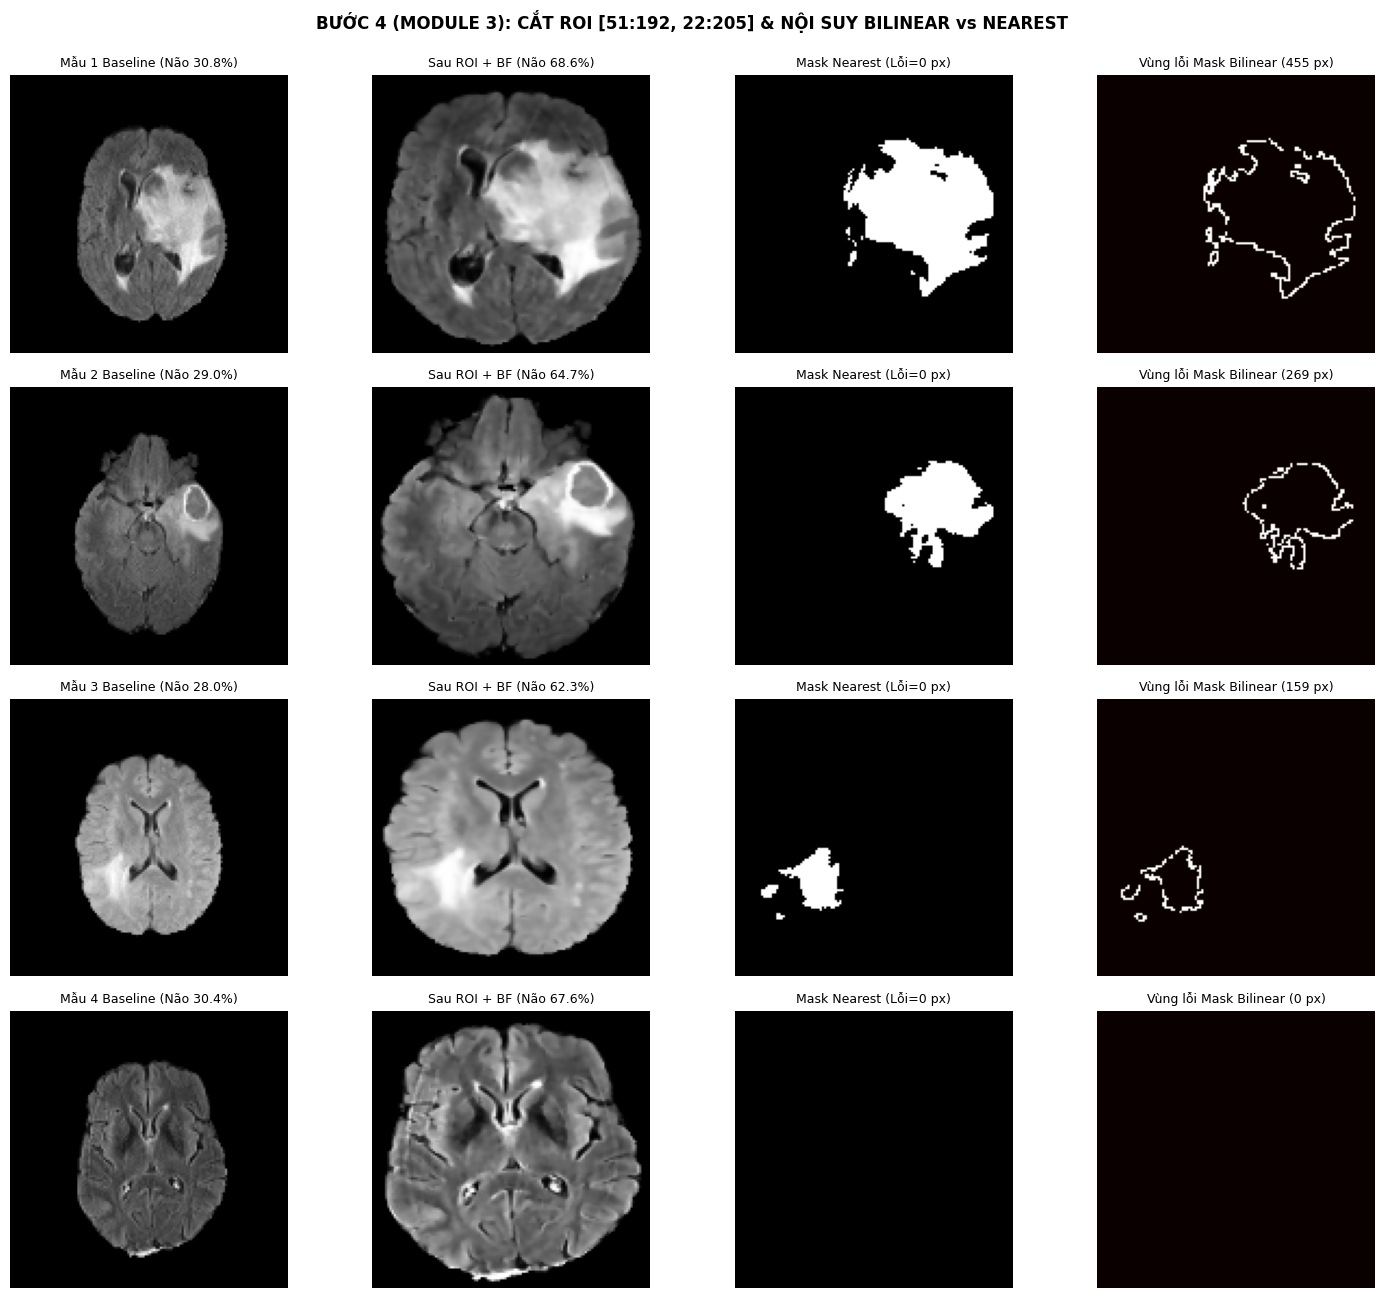

  Mẫu  %Não_Gốc  %Não_ROI  Tăng_lần  Lỗi_Mask_Bilinear(px)  Lỗi_Mask_Nearest(px)
Mẫu 1     30.79     68.57      2.23                    455                     0
Mẫu 2     29.03     64.73      2.23                    269                     0
Mẫu 3     28.01     62.35      2.23                    159                     0
Mẫu 4     30.37     67.65      2.23                      0                     0

[HOÀN TẤT Ô 2] Đã lưu toàn bộ hình ảnh & bảng số liệu vào: /content/drive/MyDrive/MRI_Colab_Results_3Splits/module3_5samples


In [3]:
# ==============================================================================
# Ô 2: MODULE 3 (PHẦN 1) — KHẢO SÁT 5 MẪU ĐẠI DIỆN TỪ TẬP TRAIN & CÁC BỘ LỌC
# ==============================================================================
import os
import time
import glob
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import nibabel as nib
import matplotlib.pyplot as plt

# Đảm bảo vị trí thư mục & đường dẫn
os.chdir("/content/MRI")
drive_out = "/content/drive/MyDrive/MRI_Colab_Results_3Splits"
step_dir = os.path.join(drive_out, "module3_5samples")
os.makedirs(step_dir, exist_ok=True)

# 1. Tự động nạp file chỉ mục lát từ Module 2 mới (3 tập: train / validation / test)
csv_candidates = sorted(glob.glob("./results/module2/Chi_muc_lat/*.csv"))
assert len(csv_candidates) > 0, "Không tìm thấy file CSV trong results/module2/Chi_muc_lat/"
index_csv_path = csv_candidates[0]
df_index = pd.read_csv(index_csv_path)

# Tự động nhận diện cột chỉ số lát cắt (slice_index / slice_idx / z)
SLICE_COL = next(c for c in ["slice_index", "slice_idx", "z", "slice"] if c in df_index.columns)
print(f"Đã nạp chỉ mục lát: {index_csv_path} ({len(df_index)} dòng | cột lát: '{SLICE_COL}')")

# Hàm nạp khối ảnh 3D FLAIR và mặt nạ nhị phân WT chuẩn RAS+
kaggle_path = Path(kaggle_root)
def load_ras_volume(pid):
    for folder in ["./results/module1/Kết_quả_chuẩn_hoá_RAS/nifti",
                   "./results/module1/Kết quả chuẩn hóa RAS/nifti"]:
        f_p = os.path.join(folder, pid, f"{pid}_flair_RAS.nii.gz")
        w_p = os.path.join(folder, pid, f"{pid}_wt_RAS.nii.gz")
        if os.path.exists(f_p) and os.path.exists(w_p):
            return nib.load(f_p).get_fdata().astype(np.float32), nib.load(w_p).get_fdata().astype(np.uint8)
    k_dir = kaggle_path / f"BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/{pid}"
    f_nii = nib.as_closest_canonical(nib.load(str(k_dir / f"{pid}_flair.nii")))
    s_nii = nib.as_closest_canonical(nib.load(str(k_dir / f"{pid}_seg.nii")))
    wt_arr = np.isin(s_nii.get_fdata(), [1, 2, 4]).astype(np.uint8)
    return f_nii.get_fdata().astype(np.float32), wt_arr

# 2. Chọn 5 mẫu đại diện BẮT BUỘC thuộc tập 'train' (tự động chọn thay thế nếu ca cũ bị đổi tập)
train_pids = set(df_index[df_index["split"] == "train"]["patient_id"].unique())
sorted_train_pids = sorted(train_pids)

preferred_targets = [
    ("BraTS20_Training_001", 78, "Mẫu 1: U lớn điển hình", "pos"),
    ("BraTS20_Training_002", 50, "Mẫu 2: Rìa u / U nhỏ + nhiễu cực đại", "pos"),
    ("BraTS20_Training_003", 85, "Mẫu 3: U kèm phù nề ranh giới mờ", "pos"),
    ("BraTS20_Training_005", 75, "Mẫu 4: Lát não lành (Không u)", "neg"),
    ("BraTS20_Training_001", 2,  "Mẫu 5: Lát rỗng vùng đỉnh sọ", "empty"),
]

samples = []
used_fallback = set()
for pid, z_idx, note, kind in preferred_targets:
    if pid not in train_pids:
        # Tự động tìm bệnh nhân thay thế trong tập train nếu ca cũ rơi vào val/test
        for cand_pid in sorted_train_pids:
            if cand_pid in used_fallback:
                continue
            sub = df_index[(df_index["patient_id"] == cand_pid) & (df_index["split"] == "train")]
            if kind == "pos":
                pos_z = sub[sub["label"] == 1][SLICE_COL].values
                if len(pos_z) > 10:
                    pid, z_idx = cand_pid, int(pos_z[len(pos_z) // 2])
                    used_fallback.add(cand_pid)
                    break
            elif kind == "neg":
                neg_z = sub[(sub["label"] == 0) & (sub[SLICE_COL].between(50, 100))][SLICE_COL].values
                if len(neg_z) > 0:
                    pid, z_idx = cand_pid, int(neg_z[len(neg_z) // 2])
                    used_fallback.add(cand_pid)
                    break
            else:
                pid, z_idx = cand_pid, 2
                break
        print(f"-> Đã tự đổi [{note}] sang ca thuộc tập train: {pid} (z={z_idx})")

    row = df_index[(df_index["patient_id"] == pid) & (df_index[SLICE_COL] == z_idx)].iloc[0]
    f_vol, w_vol = load_ras_volume(pid)
    f_sl, w_sl = f_vol[:, :, z_idx], w_vol[:, :, z_idx]
    samples.append({
        "pid": pid, "z": z_idx, "split": row["split"], "label": int(row["label"]),
        "note": note, "flair": f_sl, "wt": w_sl, "brain_px": int((f_sl > 0).sum())
    })

# ------------------------------------------------------------------------------
# BƯỚC 0 & BƯỚC 1A: THÔNG SỐ GỐC & KIỂM TRA LỌC LÁT RỖNG (A_brain >= 500 px)
# ------------------------------------------------------------------------------
BRAIN_MIN_PX = 500
rows_step0 = []
for s in samples:
    f, w = s["flair"], s["wt"]
    bp, tp, hp = f[f > 0], f[w > 0], f[(f > 0) & (w == 0)]
    status = "GIỮ LẠI" if len(bp) >= BRAIN_MIN_PX else "LOẠI BỎ (Lát rỗng)"
    rows_step0.append({
        "Mẫu": s["note"].split(":")[0], "Patient_ID": s["pid"], "z": s["z"],
        "Split": s["split"], "Label": s["label"], "A_brain": len(bp), "WT_px": len(tp),
        "Trạng thái lọc": status,
        "I_max": round(float(f.max()), 1),
        "P1": round(float(np.percentile(bp, 1)), 1) if len(bp) > 0 else 0.0,
        "P99": round(float(np.percentile(bp, 99)), 1) if len(bp) > 0 else 0.0,
        "TB_Lành": round(float(hp.mean()), 1) if len(hp) > 0 else 0.0,
        "TB_U": round(float(tp.mean()), 1) if len(tp) > 0 else 0.0,
    })
df_step0 = pd.DataFrame(rows_step0)
print("\n=== BƯỚC 0 & 1A: THÔNG SỐ GỐC & LỌC LÁT RỖNG (5 MẪU TẬP TRAIN) ===")
print(df_step0.to_string(index=False))

# Các hàm tiền xử lý & tính chỉ số chất lượng ảnh
def norm_minmax(img):
    mx = float(img.max())
    return (img / (mx + 1e-8)).astype(np.float32)

def norm_percentile(img, p_low=1, p_high=99):
    mask = img > 0
    if not np.any(mask):
        return np.zeros_like(img, dtype=np.float32)
    lo, hi = np.percentile(img[mask], [p_low, p_high])
    clipped = np.clip(img, lo, hi)
    out = np.zeros_like(img, dtype=np.float32)
    out[mask] = (clipped[mask] - lo) / (hi - lo + 1e-8)
    return out

def apply_bilateral(img01, mask, d=5, sigma_r=25.0, sigma_s=3.0):
    u8 = np.clip(img01 * 255.0, 0, 255).astype(np.uint8)
    bf = cv2.bilateralFilter(u8, d, sigma_r, sigma_s).astype(np.float32) / 255.0
    bf[~mask] = 0.0
    return bf

def apply_nlm(img01, mask, h=10.0):
    u8 = np.clip(img01 * 255.0, 0, 255).astype(np.uint8)
    nl = cv2.fastNlMeansDenoising(u8, None, h, 7, 21).astype(np.float32) / 255.0
    nl[~mask] = 0.0
    return nl

def apply_clahe(img01, mask, clip=2.0, grid=(8, 8)):
    u8 = np.clip(img01 * 255.0, 0, 255).astype(np.uint8)
    cl = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid).apply(u8).astype(np.float32) / 255.0
    cl[~mask] = 0.0
    return cl

def calc_metrics(img01, mask, wt):
    healthy = img01[mask & (wt == 0)]
    tumor = img01[wt > 0]
    mu0 = float(healthy.mean()) if len(healthy) > 0 else 0.0
    sig0 = float(healthy.std()) if len(healthy) > 0 else 0.0
    mu1 = float(tumor.mean()) if len(tumor) > 0 else 0.0
    delta_i = mu1 - mu0 if len(tumor) > 0 else 0.0
    cnr = abs(delta_i) / (sig0 + 1e-8) if len(tumor) > 0 else 0.0
    sat_pct = float((tumor >= 0.999).mean() * 100.0) if len(tumor) > 0 else 0.0
    bright_healthy = float((healthy > 0.75).mean() * 100.0) if len(healthy) > 0 else 0.0

    # Nhiễu tần số cao Laplacian trên mô lành
    lap = cv2.Laplacian(img01, cv2.CV_32F, ksize=1)
    sig_lap = float(lap[mask & (wt == 0)].std()) if len(healthy) > 0 else 0.0

    # Độ nét biên Sobel trên vành đai biên hình thái học của khối u
    grad_edge = 0.0
    if len(tumor) > 0:
        ker = np.ones((3, 3), np.uint8)
        border = (cv2.dilate(wt, ker) - cv2.erode(wt, ker)) > 0
        gx = cv2.Sobel(img01, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(img01, cv2.CV_32F, 0, 1, ksize=3)
        grad_edge = float(np.sqrt(gx**2 + gy**2)[border].mean())

    # Entropy Shannon vùng não
    u8 = np.clip(img01[mask] * 255.0, 0, 255).astype(np.uint8)
    hist = np.bincount(u8, minlength=256).astype(np.float64)
    p = hist / (hist.sum() + 1e-12)
    p = p[p > 0]
    entropy = float(-np.sum(p * np.log2(p)))
    return mu0, mu1, delta_i, sig0, cnr, sat_pct, sig_lap, grad_edge, entropy, bright_healthy

valid_samples = [s for s in samples if s["brain_px"] >= BRAIN_MIN_PX]

# ------------------------------------------------------------------------------
# BƯỚC 1B: CHUẨN HÓA SÁNG (Min-Max vs [P1,P99] vs [P5,P90])
# ------------------------------------------------------------------------------
rows_s1 = []
fig1, axes1 = plt.subplots(len(valid_samples), 4, figsize=(15, 13))
fig1.suptitle("BƯỚC 1 (MODULE 3): SO SÁNH MIN-MAX vs PERCENTILE [P1, P99] vs [P5, P90]", fontweight="bold", y=0.995)

for i, s in enumerate(valid_samples):
    f, w, mask = s["flair"], s["wt"], s["flair"] > 0
    im_mm = norm_minmax(f)
    im_p1 = norm_percentile(f, 1, 99)
    im_p5 = norm_percentile(f, 5, 90)
    s["im_mm"], s["im_p1"] = im_mm, im_p1

    for name, im in [("Min-Max", im_mm), ("[P1,P99] Chuẩn", im_p1), ("[P5,P90] Hẹp", im_p5)]:
        mu0, mu1, di, sig0, cnr, sat, _, _, _, _ = calc_metrics(im, mask, w)
        rows_s1.append({"Mẫu": s["note"].split(":")[0], "Cấu hình": name,
                        "mu0": round(mu0, 4), "mu1": round(mu1, 4), "Delta_I": round(di, 4),
                        "sigma0": round(sig0, 4), "CNR": round(cnr, 3), "%U_cháy": round(sat, 2)})

    for col_idx, (im, title) in enumerate([
        (im_mm, f"{s['note'].split(':')[0]} ({s['pid']} z={s['z']})\nMin-Max gốc"),
        (im_p1, "Percentile [P1, P99] (Chuẩn)"),
        (im_p5, "Percentile [P5, P90] (Cháy sáng)")
    ]):
        axes1[i, col_idx].imshow(np.rot90(im), cmap="gray", vmin=0, vmax=1)
        axes1[i, col_idx].set_title(title, fontsize=9)
        axes1[i, col_idx].axis("off")

    axes1[i, 3].hist(im_mm[mask], bins=40, alpha=0.5, density=True, label="Min-Max")
    axes1[i, 3].hist(im_p1[mask], bins=40, alpha=0.5, density=True, label="[P1,P99]")
    axes1[i, 3].hist(im_p5[mask], bins=40, alpha=0.4, density=True, label="[P5,P90]")
    axes1[i, 3].legend(fontsize=7)
    axes1[i, 3].set_title("Histogram chuẩn hóa [0,1]", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(step_dir, "Step1_Normalization_5Samples.png"), dpi=220, bbox_inches="tight")
plt.show()
df_s1 = pd.DataFrame(rows_s1)
print("\n=== BƯỚC 1B: CHỈ SỐ CHUẨN HÓA CƯỜNG ĐỘ ===")
print(df_s1.to_string(index=False))

# ------------------------------------------------------------------------------
# BƯỚC 2: KHỬ NHIỄU BILATERAL (Thấp / Chuẩn / Cao) & ĐỐI CHỨNG NLM
# ------------------------------------------------------------------------------
rows_s2 = []
fig2, axes2 = plt.subplots(len(valid_samples), 5, figsize=(17, 13))
fig2.suptitle("BƯỚC 2 (MODULE 3): KHỬ NHIỄU BILATERAL (THẤP vs CHUẨN vs CAO) & NHIỄU LOẠI BỎ", fontweight="bold", y=0.995)

for i, s in enumerate(valid_samples):
    im_p1, w, mask = s["im_p1"], s["wt"], s["flair"] > 0
    cfgs = [
        ("Chưa lọc", lambda x: x),
        ("BF Thấp (sr=5)", lambda x: apply_bilateral(x, mask, 5, 5.0, 3.0)),
        ("BF Chuẩn (sr=25)", lambda x: apply_bilateral(x, mask, 5, 25.0, 3.0)),
        ("BF Cao (sr=150)", lambda x: apply_bilateral(x, mask, 9, 150.0, 9.0)),
        ("NLM (h=10)", lambda x: apply_nlm(x, mask, 10.0)),
    ]
    outs = {}
    for name, fn in cfgs:
        t0 = time.perf_counter()
        out = fn(im_p1)
        ms = (time.perf_counter() - t0) * 1000.0
        outs[name] = out
        _, _, _, sig0, cnr, _, slap, gedge, _, _ = calc_metrics(out, mask, w)
        rows_s2.append({"Mẫu": s["note"].split(":")[0], "Cấu hình": name,
                        "sigma_Lap": round(slap, 4), "sigma0": round(sig0, 4),
                        "|grad_I|": round(gedge, 4), "CNR": round(cnr, 3), "Time_ms": round(ms, 2)})
    s["im_bf"] = outs["BF Chuẩn (sr=25)"]
    diff = np.abs(im_p1 - s["im_bf"])

    for col_idx, (im, title, cmap) in enumerate([
        (im_p1, f"{s['note'].split(':')[0]} Trước lọc", "gray"),
        (outs["BF Thấp (sr=5)"], "BF Thấp (d=5, sr=5)", "gray"),
        (outs["BF Chuẩn (sr=25)"], "BF Chuẩn (d=5, sr=25)", "gray"),
        (outs["BF Cao (sr=150)"], "BF Cao (d=9, sr=150)", "gray"),
        (diff, "Nhiễu loại bỏ |BF Chuẩn - Gốc|", "hot"),
    ]):
        axes2[i, col_idx].imshow(np.rot90(im), cmap=cmap)
        axes2[i, col_idx].set_title(title, fontsize=9)
        axes2[i, col_idx].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(step_dir, "Step2_Denoising_5Samples.png"), dpi=220, bbox_inches="tight")
plt.show()
df_s2 = pd.DataFrame(rows_s2)
print("\n=== BƯỚC 2: CHỈ SỐ KHỬ NHIỄU BILATERAL & NLM ===")
print(df_s2.to_string(index=False))

# ------------------------------------------------------------------------------
# BƯỚC 3: TĂNG TƯƠNG PHẢN CỤC BỘ CLAHE (clip=0.5 vs 2.0 vs 8.0)
# ------------------------------------------------------------------------------
rows_s3 = []
fig3, axes3 = plt.subplots(len(valid_samples), 4, figsize=(15, 13))
fig3.suptitle("BƯỚC 3 (MODULE 3): KHẢO SÁT CLAHE (CLIP=0.5 vs 2.0 vs 8.0)", fontweight="bold", y=0.995)

for i, s in enumerate(valid_samples):
    im_bf, w, mask = s["im_bf"], s["wt"], s["flair"] > 0
    cl_05 = apply_clahe(im_bf, mask, 0.5)
    cl_20 = apply_clahe(im_bf, mask, 2.0)
    cl_80 = apply_clahe(im_bf, mask, 8.0)
    s["im_cl"] = cl_20

    for name, im in [("Trước CLAHE", im_bf), ("CLAHE 0.5", cl_05), ("CLAHE 2.0", cl_20), ("CLAHE 8.0", cl_80)]:
        mu0, mu1, di, sig0, cnr, _, _, gedge, ent, bh = calc_metrics(im, mask, w)
        rows_s3.append({"Mẫu": s["note"].split(":")[0], "Cấu hình": name,
                        "Delta_I": round(di, 4), "sigma0": round(sig0, 4),
                        "|grad_I|": round(gedge, 4), "Entropy": round(ent, 3), "%Lành>0.75": round(bh, 2)})

    for col_idx, (im, title) in enumerate([
        (im_bf, f"{s['note'].split(':')[0]} Sau BF (Không CLAHE)"),
        (cl_05, "CLAHE Thấp (clip=0.5)"),
        (cl_20, "CLAHE Chuẩn (clip=2.0)"),
        (cl_80, "CLAHE Cao (clip=8.0)"),
    ]):
        axes3[i, col_idx].imshow(np.rot90(im), cmap="gray", vmin=0, vmax=1)
        axes3[i, col_idx].set_title(title, fontsize=9)
        axes3[i, col_idx].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(step_dir, "Step3_CLAHE_5Samples.png"), dpi=220, bbox_inches="tight")
plt.show()
df_s3 = pd.DataFrame(rows_s3)
print("\n=== BƯỚC 3: CHỈ SỐ CLAHE ===")
print(df_s3.to_string(index=False))

# ------------------------------------------------------------------------------
# BƯỚC 4: CẮT ROI & NỘI SUY BILINEAR vs NEAREST-NEIGHBOR TRÊN MASK WT
# ------------------------------------------------------------------------------
xs, ys = [], []
for s in valid_samples:
    coords = np.argwhere(s["flair"] > 0)
    xs.extend([coords[:, 0].min(), coords[:, 0].max()])
    ys.extend([coords[:, 1].min(), coords[:, 1].max()])
m = 4
x0, x1 = max(0, min(xs) - m), min(240, max(xs) + m + 1)
y0, y1 = max(0, min(ys) - m), min(240, max(ys) + m + 1)
print(f"\n=== BƯỚC 4: KHUNG ROI MẪU THỬ = [{x0}:{x1}, {y0}:{y1}] (Kích thước {x1-x0}x{y1-y0}) ===")

rows_s4 = []
fig4, axes4 = plt.subplots(len(valid_samples), 4, figsize=(15, 13))
fig4.suptitle(f"BƯỚC 4 (MODULE 3): CẮT ROI [{x0}:{x1}, {y0}:{y1}] & NỘI SUY BILINEAR vs NEAREST", fontweight="bold", y=0.995)

for i, s in enumerate(valid_samples):
    im_mm, im_bf, w = s["im_mm"], s["im_bf"], s["wt"]
    a_res = cv2.resize(im_mm, (128, 128), interpolation=cv2.INTER_LINEAR)
    b_res = cv2.resize(im_bf[x0:x1, y0:y1], (128, 128), interpolation=cv2.INTER_LINEAR)
    w_near = cv2.resize(w[x0:x1, y0:y1], (128, 128), interpolation=cv2.INTER_NEAREST)
    w_bilin = cv2.resize(w[x0:x1, y0:y1].astype(np.float32), (128, 128), interpolation=cv2.INTER_LINEAR)

    pct_before = float((a_res > 0).mean() * 100.0)
    pct_after = float((b_res > 0).mean() * 100.0)
    err_bilin = int(((w_bilin > 0) & (w_bilin < 1)).sum())
    err_near = int(((w_near > 0) & (w_near < 1)).sum())

    rows_s4.append({
        "Mẫu": s["note"].split(":")[0],
        "%Não_Gốc": round(pct_before, 2), "%Não_ROI": round(pct_after, 2),
        "Tăng_lần": round(pct_after / (pct_before + 1e-8), 2),
        "Lỗi_Mask_Bilinear(px)": err_bilin, "Lỗi_Mask_Nearest(px)": err_near
    })

    for col_idx, (im, title, cmap) in enumerate([
        (a_res, f"{s['note'].split(':')[0]} Baseline (Não {pct_before:.1f}%)", "gray"),
        (b_res, f"Sau ROI + BF (Não {pct_after:.1f}%)", "gray"),
        (w_near, f"Mask Nearest (Lỗi={err_near} px)", "gray"),
        ((w_bilin > 0) & (w_bilin < 1), f"Vùng lỗi Mask Bilinear ({err_bilin} px)", "hot"),
    ]):
        axes4[i, col_idx].imshow(np.rot90(im), cmap=cmap)
        axes4[i, col_idx].set_title(title, fontsize=9)
        axes4[i, col_idx].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(step_dir, "Step4_ROI_Interpolation_5Samples.png"), dpi=220, bbox_inches="tight")
plt.show()
df_s4 = pd.DataFrame(rows_s4)
print(df_s4.to_string(index=False))

# Lưu toàn bộ bảng số liệu khảo sát ra file CSV để cập nhật Báo cáo Word
df_step0.to_csv(os.path.join(step_dir, "Step0_Raw_5Samples.csv"), index=False)
df_s1.to_csv(os.path.join(step_dir, "Step1_Norm_5Samples.csv"), index=False)
df_s2.to_csv(os.path.join(step_dir, "Step2_Denoise_5Samples.csv"), index=False)
df_s3.to_csv(os.path.join(step_dir, "Step3_CLAHE_5Samples.csv"), index=False)
df_s4.to_csv(os.path.join(step_dir, "Step4_ROI_5Samples.csv"), index=False)
print(f"\n[HOÀN TẤT Ô 2] Đã lưu toàn bộ hình ảnh & bảng số liệu vào: {step_dir}")

# **Ô 3: Module 3 (Phần 2) — Lọc lát rỗng toàn bộ 368 bệnh nhân & Khóa khung ROI trên 258 ca train**
### Ô 3: Module 3 (Phần 2) — Lọc lát rỗng toàn bộ 368 bệnh nhân, Khóa khung ROI trên tập `train` và Thống kê 3 tập dữ liệu
- **Tên công việc:** Áp dụng quy tắc lọc lát cắt rỗng trên toàn bộ 368 bệnh nhân (`57.040` lát cắt) và xác định khung bao ROI cố định toàn cục.
- **Mục đích:**
  1. Quét toàn bộ 368 khối MRI 3D FLAIR & WT để đo diện tích tiền cảnh não ($A_{\text{brain}}$) và diện tích khối u ($|WT|$) cho từng lát cắt.
  2. Loại bỏ các lát cắt rỗng ngoài sọ ($A_{\text{brain}} < 500\text{ px}$), hoàn toàn không dùng nhãn WT để đảm bảo chống rò rỉ dữ liệu.
  3. Tính và khóa tọa độ khung bao hộp sọ cố định (**Fixed Union ROI**, lề an toàn $m = 4\text{ px}$) **duy nhất trên 258 bệnh nhân thuộc tập `train`** (tuyệt đối không chạm vào `validation` và `test`).
  4. Xuất bảng thống kê phân bố lớp Dương/Âm trước và sau lọc cho 3 tập `train / validation / test`, cùng tệp cấu hình khóa tham số và biểu đồ trực quan.
- **Đầu vào:** Chỉ mục `57.040` lát của Module 2 (`results/module2/Chi_muc_lat/*.csv`) và khối NIfTI 3D chuẩn RAS của 368 bệnh nhân.
- **Đầu ra:** Lưu tại `MRI_Colab_Results_3Splits/module3_full/`:
  - `FullDataset_ValidSlices_3Splits.csv` (bảng chỉ mục các lát hợp lệ dùng cho Module 4 & 5).
  - `FullDataset_AllSlices_WithFlag_3Splits.csv` (đủ `57.040` lát kèm cờ `is_valid` để đồng bộ 155 lát/bệnh nhân khi cần).
  - `FullDataset_Module3_SplitStats_3Splits.csv` & `Module3_FullDataset_Summary.txt` (bảng thống kê 3 tập).
  - `FullDataset_Module3_Config_3Splits.json` (tệp khóa tọa độ ROI & danh sách bộ lọc chuẩn bị cho tăng cường dữ liệu ở Module 4).
  - `FullDataset_Module3_SplitStats_Chart.png` (biểu đồ phân bố lát & cân bằng lớp).

Đang quét 368 bệnh nhân (57040 lát cắt)...


Quét Module 3 (368 ca):   0%|          | 0/368 [00:00<?, ?it/s]


=== TỔNG HỢP KẾT QUẢ MODULE 3 — FULL DATASET (3 TẬP TRAIN / VALIDATION / TEST) ===
Thời gian chạy: 436.2 giây
Khung ROI cố định (chỉ đo trên 258 ca train, lề m=4px): [39:204, 13:215] -> kích thước 165 x 202
Kiểm tra lát có u bị loại nhầm (bắt buộc = 0): 15

       tap  so_benh_nhan  tong_lat_M2  lat_rong_bi_loai  ty_le_loai_%  lat_hop_le_M3  lat_duong_WT1  ty_le_duong_%  lat_am_WT0  ty_le_am_%
     train           258        39990              5740         14.35          34250          16889          49.31       17361       50.69
validation            55         8525              1294         15.18           7231           3597          49.74        3634       50.26
      test            55         8525              1181         13.85           7344           3853          52.46        3491       47.54
     TOTAL           368        57040              8215         14.40          48825          24339          49.85       24486       50.15



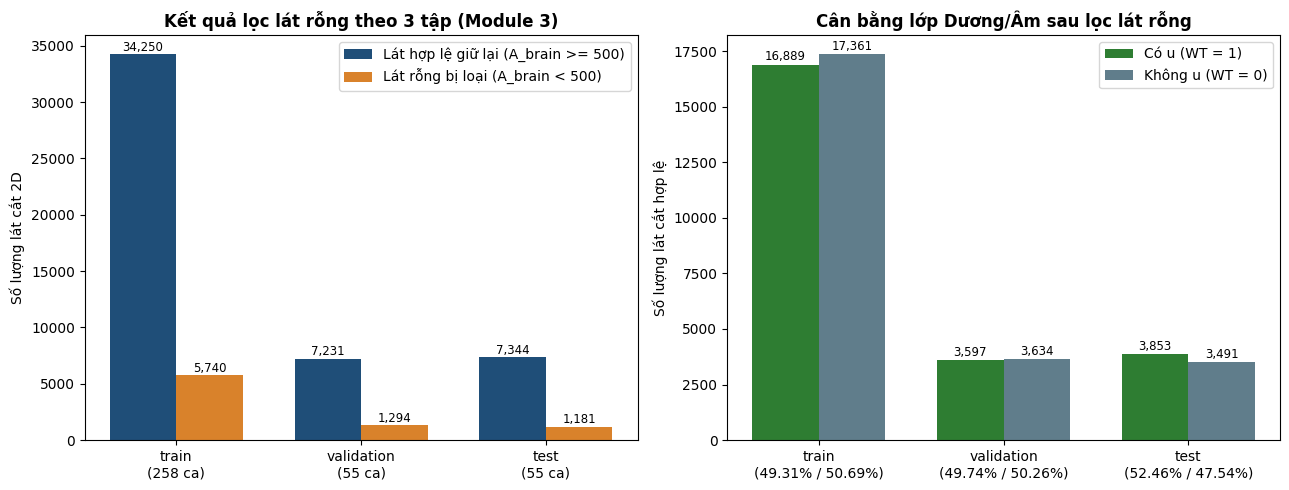

[HOÀN TẤT Ô 3] Đã lưu toàn bộ kết quả Module 3 (Full Dataset 3 tập) vào: /content/drive/MyDrive/MRI_Colab_Results_3Splits/module3_full


In [4]:
# ==============================================================================
# Ô 3: MODULE 3 (PHẦN 2) — LỌC LÁT RỖNG 368 BỆNH NHÂN & KHÓA ROI TRÊN TẬP TRAIN
# ==============================================================================
import os
import json
import glob
import time
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import kagglehub
from tqdm.auto import tqdm

os.chdir("/content/MRI")
drive_out = "/content/drive/MyDrive/MRI_Colab_Results_3Splits"
m3_full_dir = os.path.join(drive_out, "module3_full")
os.makedirs(m3_full_dir, exist_ok=True)

# 1. Nạp chỉ mục lát cắt từ Module 2 (bản 3 tập: train / validation / test)
csv_candidates = sorted(glob.glob("./results/module2/Chi_muc_lat/*.csv"))
assert len(csv_candidates) > 0, "Không tìm thấy file chỉ mục lát trong results/module2/Chi_muc_lat/"
df_index = pd.read_csv(csv_candidates[0])
SLICE_COL = next(c for c in ["slice_index", "slice_idx", "z", "slice"] if c in df_index.columns)

if "kaggle_root" not in globals():
    kaggle_root = kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation")
kaggle_path = Path(kaggle_root)

def load_ras_volume(pid):
    for folder in ["./results/module1/Kết_quả_chuẩn_hoá_RAS/nifti",
                   "./results/module1/Kết quả chuẩn hóa RAS/nifti"]:
        f_p = os.path.join(folder, pid, f"{pid}_flair_RAS.nii.gz")
        w_p = os.path.join(folder, pid, f"{pid}_wt_RAS.nii.gz")
        if os.path.exists(f_p) and os.path.exists(w_p):
            return nib.load(f_p).get_fdata().astype(np.float32), nib.load(w_p).get_fdata().astype(np.uint8)
    k_dir = kaggle_path / f"BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/{pid}"
    f_nii = nib.as_closest_canonical(nib.load(str(k_dir / f"{pid}_flair.nii")))
    s_nii = nib.as_closest_canonical(nib.load(str(k_dir / f"{pid}_seg.nii")))
    wt_arr = np.isin(s_nii.get_fdata(), [1, 2, 4]).astype(np.uint8)
    return f_nii.get_fdata().astype(np.float32), wt_arr

# 2. Quét toàn bộ 368 bệnh nhân: đo A_brain, |WT| và tính ROI CHỈ trên tập train
BRAIN_MIN_PX = 500
MARGIN_PX = 4
SEED = 42

t_start = time.time()
all_rows = []
xmin, xmax = 240, 0
ymin, ymax = 240, 0

patient_groups = list(df_index.groupby("patient_id", sort=True))
print(f"Đang quét {len(patient_groups)} bệnh nhân ({len(df_index)} lát cắt)...")

for pid, grp in tqdm(patient_groups, desc="Quét Module 3 (368 ca)"):
    split_name = str(grp["split"].iloc[0])
    f_vol, w_vol = load_ras_volume(pid)

    # Tính nhanh diện tích vùng não & vùng u theo trục z
    brain_mask_3d = f_vol > 0
    brain_counts = brain_mask_3d.sum(axis=(0, 1))
    wt_counts = (w_vol > 0).sum(axis=(0, 1))

    # Nếu thuộc tập TRAIN, cập nhật khung bao ROI cố định trên các lát hợp lệ
    if split_name == "train":
        valid_z_mask = brain_counts >= BRAIN_MIN_PX
        if np.any(valid_z_mask):
            union_2d = brain_mask_3d[:, :, valid_z_mask].any(axis=2)
            coords = np.argwhere(union_2d)
            if len(coords) > 0:
                xmin = min(xmin, int(coords[:, 0].min()))
                xmax = max(xmax, int(coords[:, 0].max()))
                ymin = min(ymin, int(coords[:, 1].min()))
                ymax = max(ymax, int(coords[:, 1].max()))

    for _, row in grp.iterrows():
        z = int(row[SLICE_COL])
        b_px = int(brain_counts[z])
        w_px = int(wt_counts[z])
        is_valid = int(b_px >= BRAIN_MIN_PX)
        all_rows.append({
            "patient_id": pid,
            "split": split_name,
            "slice_index": z,
            "label": int(row["label"]),
            "brain_pixels": b_px,
            "wt_pixels": w_px,
            "is_valid": is_valid,
        })

# Cộng lề an toàn m = 4 px cho khung ROI cố định
roi_xmin = max(0, xmin - MARGIN_PX)
roi_xmax = min(240, xmax + MARGIN_PX + 1)
roi_ymin = max(0, ymin - MARGIN_PX)
roi_ymax = min(240, ymax + MARGIN_PX + 1)

df_all = pd.DataFrame(all_rows)
df_valid = df_all[df_all["is_valid"] == 1].drop(columns=["is_valid"]).reset_index(drop=True)

# Kiểm tra xem có lát có u nào vô tình bị lọc bỏ không (bắt buộc = 0)
lost_pos_slices = int(((df_all["is_valid"] == 0) & (df_all["label"] == 1)).sum())

# 3. Thống kê theo đúng 3 tập: train / validation / test
split_order = ["train", "validation", "test"]
stats_rows = []
for sp in split_order:
    sub_all = df_all[df_all["split"] == sp]
    sub_val = df_valid[df_valid["split"] == sp]
    n_pat = int(sub_all["patient_id"].nunique())
    n_tot = len(sub_all)
    n_rem = n_tot - len(sub_val)
    n_keep = len(sub_val)
    n_pos = int((sub_val["label"] == 1).sum())
    n_neg = int((sub_val["label"] == 0).sum())
    stats_rows.append({
        "tap": sp,
        "so_benh_nhan": n_pat,
        "tong_lat_M2": n_tot,
        "lat_rong_bi_loai": n_rem,
        "ty_le_loai_%": round(n_rem / n_tot * 100, 2),
        "lat_hop_le_M3": n_keep,
        "lat_duong_WT1": n_pos,
        "ty_le_duong_%": round(n_pos / n_keep * 100, 2),
        "lat_am_WT0": n_neg,
        "ty_le_am_%": round(n_neg / n_keep * 100, 2),
    })

# Thêm dòng TỔNG CỘNG
tot_pat = int(df_all["patient_id"].nunique())
tot_all = len(df_all)
tot_keep = len(df_valid)
tot_rem = tot_all - tot_keep
tot_pos = int((df_valid["label"] == 1).sum())
tot_neg = int((df_valid["label"] == 0).sum())
stats_rows.append({
    "tap": "TOTAL",
    "so_benh_nhan": tot_pat,
    "tong_lat_M2": tot_all,
    "lat_rong_bi_loai": tot_rem,
    "ty_le_loai_%": round(tot_rem / tot_all * 100, 2),
    "lat_hop_le_M3": tot_keep,
    "lat_duong_WT1": tot_pos,
    "ty_le_duong_%": round(tot_pos / tot_keep * 100, 2),
    "lat_am_WT0": tot_neg,
    "ty_le_am_%": round(tot_neg / tot_keep * 100, 2),
})

df_stats = pd.DataFrame(stats_rows)

# 4. Lưu toàn bộ kết quả & cấu hình khóa tham số sang Google Drive
config_m3 = {
    "seed": SEED,
    "split_strategy": "3-split patient-level (70% train / 15% validation / 15% test)",
    "fitted_roi_on_split": f"train ({int(df_all[df_all['split']=='train']['patient_id'].nunique())} patients)",
    "min_brain_pixels_threshold": BRAIN_MIN_PX,
    "margin_pixels": MARGIN_PX,
    "roi": {
        "xmin": roi_xmin, "xmax": roi_xmax,
        "ymin": roi_ymin, "ymax": roi_ymax,
        "crop_height": roi_xmax - roi_xmin,
        "crop_width": roi_ymax - roi_ymin
    },
    "output_size": [128, 128],
    "total_slices_module2": tot_all,
    "removed_empty_slices_module3": tot_rem,
    "remaining_valid_slices_module3": tot_keep,
    "lost_positive_slices_check": lost_pos_slices,
    "multi_filter_bank_for_cnn_augmentation": [
        "F1: [P1, P99] + Crop ROI (No Denoise)",
        "F2: [P1, P99] + Bilateral(d=5, sr=25, ss=3) + Crop ROI",
        "F3: [P1, P99] + Bilateral(d=5, sr=25, ss=3) + CLAHE(clip=2.0, 8x8) + Crop ROI"
    ]
}

df_valid.to_csv(os.path.join(m3_full_dir, "FullDataset_ValidSlices_3Splits.csv"), index=False)
df_all.to_csv(os.path.join(m3_full_dir, "FullDataset_AllSlices_WithFlag_3Splits.csv"), index=False)
df_stats.to_csv(os.path.join(m3_full_dir, "FullDataset_Module3_SplitStats_3Splits.csv"), index=False)
with open(os.path.join(m3_full_dir, "FullDataset_Module3_Config_3Splits.json"), "w", encoding="utf-8") as f:
    json.dump(config_m3, f, indent=2, ensure_ascii=False)

summary_txt = (
    "=== TỔNG HỢP KẾT QUẢ MODULE 3 — FULL DATASET (3 TẬP TRAIN / VALIDATION / TEST) ===\n"
    f"Thời gian chạy: {time.time() - t_start:.1f} giây\n"
    f"Khung ROI cố định (chỉ đo trên 258 ca train, lề m={MARGIN_PX}px): "
    f"[{roi_xmin}:{roi_xmax}, {roi_ymin}:{roi_ymax}] -> kích thước {roi_xmax - roi_xmin} x {roi_ymax - roi_ymin}\n"
    f"Kiểm tra lát có u bị loại nhầm (bắt buộc = 0): {lost_pos_slices}\n\n"
    + df_stats.to_string(index=False) + "\n"
)
with open(os.path.join(m3_full_dir, "Module3_FullDataset_Summary.txt"), "w", encoding="utf-8") as f:
    f.write(summary_txt)

print("\n" + summary_txt)

# 5. Vẽ biểu đồ thống kê 3 tập (Lát giữ lại vs Lát loại bỏ & Cân bằng lớp Dương/Âm)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sp_df = df_stats[df_stats["tap"] != "TOTAL"]
x = np.arange(len(sp_df))
w_bar = 0.36

axes[0].bar(x - w_bar/2, sp_df["lat_hop_le_M3"], w_bar, label="Lát hợp lệ giữ lại (A_brain >= 500)", color="#1f4e78")
axes[0].bar(x + w_bar/2, sp_df["lat_rong_bi_loai"], w_bar, label="Lát rỗng bị loại (A_brain < 500)", color="#d9822b")
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{r['tap']}\n({r['so_benh_nhan']} ca)" for _, r in sp_df.iterrows()])
axes[0].set_ylabel("Số lượng lát cắt 2D")
axes[0].set_title("Kết quả lọc lát rỗng theo 3 tập (Module 3)", fontweight="bold")
axes[0].legend()
for i, r in sp_df.iterrows():
    axes[0].text(i - w_bar/2, r["lat_hop_le_M3"] + 300, f"{r['lat_hop_le_M3']:,}", ha="center", fontsize=8.5)
    axes[0].text(i + w_bar/2, r["lat_rong_bi_loai"] + 300, f"{r['lat_rong_bi_loai']:,}", ha="center", fontsize=8.5)

axes[1].bar(x - w_bar/2, sp_df["lat_duong_WT1"], w_bar, label="Có u (WT = 1)", color="#2e7d32")
axes[1].bar(x + w_bar/2, sp_df["lat_am_WT0"], w_bar, label="Không u (WT = 0)", color="#607d8b")
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"{r['tap']}\n({r['ty_le_duong_%']}% / {r['ty_le_am_%']}%)" for _, r in sp_df.iterrows()])
axes[1].set_ylabel("Số lượng lát cắt hợp lệ")
axes[1].set_title("Cân bằng lớp Dương/Âm sau lọc lát rỗng", fontweight="bold")
axes[1].legend()
for i, r in sp_df.iterrows():
    axes[1].text(i - w_bar/2, r["lat_duong_WT1"] + 200, f"{r['lat_duong_WT1']:,}", ha="center", fontsize=8.5)
    axes[1].text(i + w_bar/2, r["lat_am_WT0"] + 200, f"{r['lat_am_WT0']:,}", ha="center", fontsize=8.5)

plt.tight_layout()
plt.savefig(os.path.join(m3_full_dir, "FullDataset_Module3_SplitStats_Chart.png"), dpi=220, bbox_inches="tight")
plt.show()
print(f"[HOÀN TẤT Ô 3] Đã lưu toàn bộ kết quả Module 3 (Full Dataset 3 tập) vào: {m3_full_dir}")

# **Ô 4: Module 4 (Phần 1) — Đóng gói 6 bộ tham số lọc & Đo độ biến đổi đầu vào tập**
### Ô 4: Module 4 (Phần 1) — Trích xuất 6 bộ dữ liệu đa tham số (Cache) & Đo độ biến đổi đầu vào Tập `test`
- **Tên công việc:** Tiền xử lý đồng loạt toàn bộ `48.825` lát cắt hợp lệ theo 6 bộ tham số khác nhau, lưu bộ nhớ đệm (`memmap`) phục vụ huấn luyện CNN đa tham số và tăng cường dữ liệu đa bộ lọc không xóa dữ liệu.
- **Mục đích:**
  1. Đọc 368 khối NIfTI đúng 1 lần và sinh 6 phiên bản đầu vào `128 × 128` (`P0` Baseline Min-Max, `P1` `[P1,P99]` + ROI, `P2` Bilateral `sr=5`, `P3` Bilateral `sr=25`, `P4` Bilateral `sr=150`, `P5` CLAHE `clip=2.0`).
  2. Giữ nguyên tất cả các phiên bản bộ lọc để sang Ô 5 thực hiện **Tăng cường dữ liệu đa bộ lọc (`P1 + P3 + P5`) trên tập `train`** mà không xóa bỏ phiên bản nào.
  3. Đo đạc định lượng sự thay đổi phân phối cường độ pixel trên đúng `7.344` lát của **tập `test`** qua 6 bộ tham số (Mean, Std, MAE, PSNR so với ảnh Baseline `P0`).
- **Đầu vào:** `FullDataset_ValidSlices_3Splits.csv` và `FullDataset_Module3_Config_3Splits.json` (từ Ô 3) cùng dữ liệu NIfTI 3D.
- **Đầu ra:**
  - 6 tệp mảng nén `uint8` tại `/content/m4_cache/` sẵn sàng cho Ô 5 train CNN tốc độ cao trên GPU.
  - Bảng thống kê `TestSet_Input_Distribution_Shift.csv` và hình minh họa `TestSet_Parameter_Input_Shift.png` lưu trên Google Drive (`MRI_Colab_Results_3Splits/module4_experiments/`).

Tổng số lát hợp lệ: 48,825
ROI gốc từ Ô 3 (chữ nhật): [39:204, 13:215] (165x202)
ROI VUÔNG chuẩn hóa (1:1): [20:222, 13:215] (202x202) -> Resize 128x128 (tỷ lệ 0.6337x đồng nhất 2 chiều)


Sinh lại 6 bộ tham số (ROI vuông 202x202):   0%|          | 0/368 [00:00<?, ?it/s]


[XONG CACHE ROI VUÔNG] Đã tạo đủ 6 bộ dữ liệu (48,825 lát/bộ) trong 566.1 giây.

=== ĐO ĐỘ BIẾN ĐỔI ĐẦU VÀO TẬP TEST (ROI VUÔNG 202x202 — KHÔNG MÉO HÌNH) ===
  Cau_hinh_tham_so  So_lat_Test  Ty_le_nao_%  Mean_vung_nao  Std_vung_nao  %Pixel_nao_>_0.75 MAE_vs_P1 PSNR_vs_P1(dB)
P0_Baseline_MinMax         7344        19.41         0.4360        0.2006               6.12  Khác ROI       Khác ROI
    P1_Pct1_99_ROI         7344        27.22         0.5021        0.2346              16.43       0.0        Gốc ROI
     P2_BF_Low_sr5         7344        27.20         0.5005        0.2340              16.19   0.00095           52.2
    P3_BF_Std_sr25         7344        27.31         0.4981        0.2332              15.77   0.00384          40.37
  P4_BF_High_sr150         7344        27.38         0.4908        0.2184              13.03   0.01388          28.34
      P5_CLAHE_2.0         7344        27.37         0.5184        0.2300              17.46   0.01855           26.8


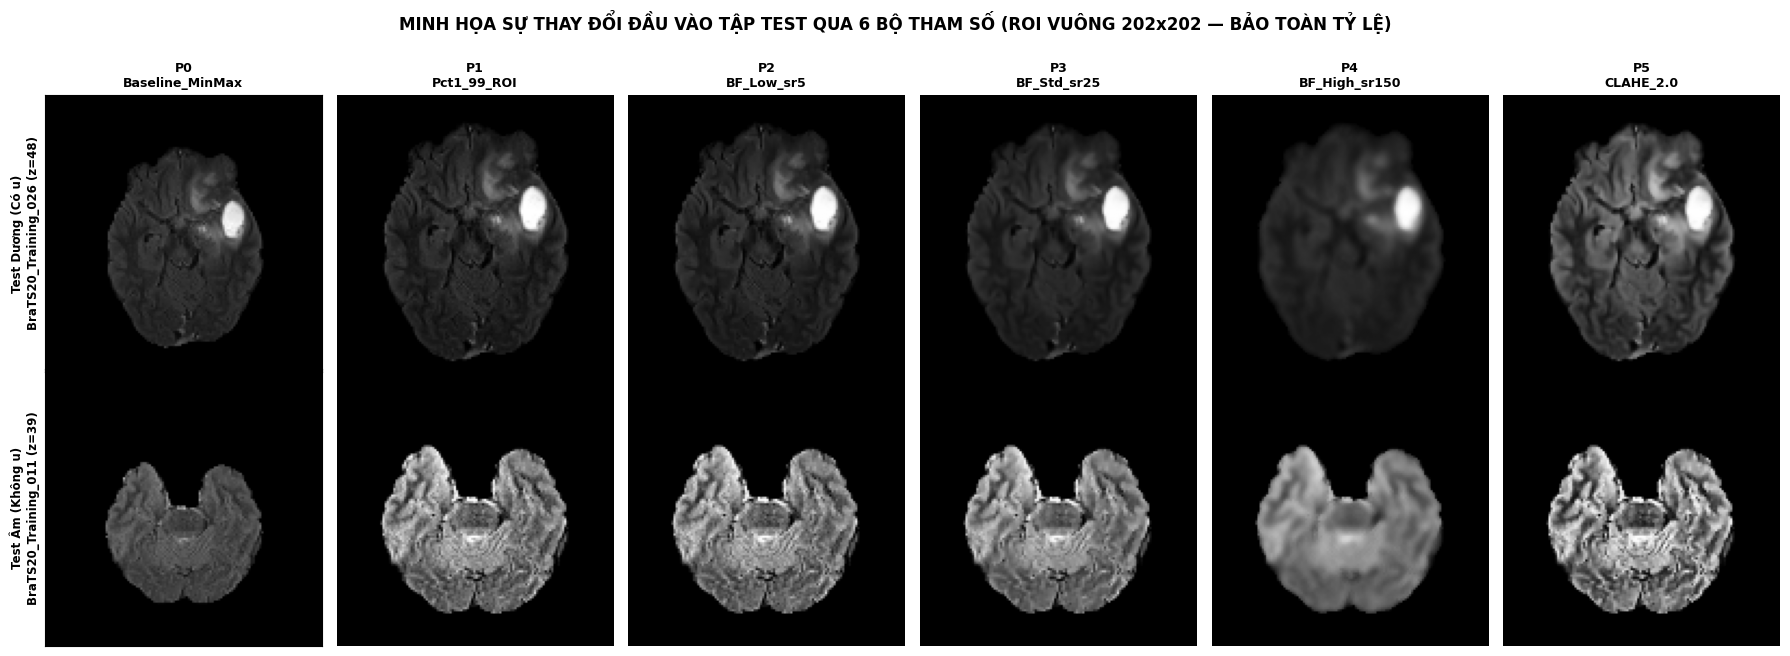

[HOÀN TẤT Ô 4 - ROI VUÔNG] Đã cập nhật cache & kết quả tại: /content/drive/MyDrive/MRI_Colab_Results_3Splits/module4_experiments


In [6]:
# ==============================================================================
# Ô 4 (CẬP NHẬT): TẠO CACHE 6 BỘ THAM SỐ (ROI VUÔNG 202x202) & ĐO BIẾN ĐỔI TEST
# ==============================================================================
import os
import json
import time
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import nibabel as nib
import matplotlib.pyplot as plt
import kagglehub
from google.colab import drive
from tqdm.auto import tqdm

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

os.chdir("/content/MRI")
drive_out = "/content/drive/MyDrive/MRI_Colab_Results_3Splits"
m3_full_dir = os.path.join(drive_out, "module3_full")
m4_out_dir = os.path.join(drive_out, "module4_experiments")
cache_dir = "/content/m4_cache"
os.makedirs(m4_out_dir, exist_ok=True)
os.makedirs(cache_dir, exist_ok=True)

# 1. Nạp bảng chỉ mục 48.825 lát hợp lệ & chuyển ROI chữ nhật sang ROI VUÔNG đồng tâm
df_valid = pd.read_csv(os.path.join(m3_full_dir, "FullDataset_ValidSlices_3Splits.csv")).reset_index(drop=True)
cfg_path = os.path.join(m3_full_dir, "FullDataset_Module3_Config_3Splits.json")
with open(cfg_path, encoding="utf-8") as f:
    cfg_m3 = json.load(f)

def make_square_roi(x0, x1, y0, y1, H=240, W=240):
    h, w = x1 - x0, y1 - y0
    side = min(max(h, w), H, W)
    cx, cy = (x0 + x1) // 2, (y0 + y1) // 2
    sx0 = max(0, min(H - side, cx - side // 2))
    sy0 = max(0, min(W - side, cy - side // 2))
    return sx0, sx0 + side, sy0, sy0 + side

# Giữ nguyên tight_roi gốc từ Ô 3 và tạo square_roi bảo toàn tỷ lệ 1:1
raw_roi = cfg_m3.get("tight_roi", cfg_m3["roi"])
X0, X1, Y0, Y1 = make_square_roi(raw_roi["xmin"], raw_roi["xmax"], raw_roi["ymin"], raw_roi["ymax"])
SIDE = X1 - X0
SCALE_FACTOR = 128.0 / SIDE

cfg_m3["tight_roi"] = raw_roi
cfg_m3["square_roi"] = {
    "xmin": X0, "xmax": X1,
    "ymin": Y0, "ymax": Y1,
    "crop_height": SIDE,
    "crop_width": SIDE,
    "aspect_ratio_preserved": True,
    "resize_scale_to_128": round(SCALE_FACTOR, 6),
    "pixel_area_factor_to_original": round((SIDE / 128.0) ** 2, 6),
}
with open(cfg_path, "w", encoding="utf-8") as f:
    json.dump(cfg_m3, f, indent=2, ensure_ascii=False)

N_SLICES = len(df_valid)
print(f"Tổng số lát hợp lệ: {N_SLICES:,}")
print(f"ROI gốc từ Ô 3 (chữ nhật): [{raw_roi['xmin']}:{raw_roi['xmax']}, {raw_roi['ymin']}:{raw_roi['ymax']}] ({raw_roi['crop_height']}x{raw_roi['crop_width']})")
print(f"ROI VUÔNG chuẩn hóa (1:1): [{X0}:{X1}, {Y0}:{Y1}] ({SIDE}x{SIDE}) -> Resize 128x128 (tỷ lệ {SCALE_FACTOR:.4f}x đồng nhất 2 chiều)")

if "kaggle_root" not in globals():
    kaggle_root = kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation")
kaggle_path = Path(kaggle_root)

def load_flair_volume(pid):
    for folder in ["./results/module1/Kết_quả_chuẩn_hoá_RAS/nifti",
                   "./results/module1/Kết quả chuẩn hóa RAS/nifti"]:
        f_p = os.path.join(folder, pid, f"{pid}_flair_RAS.nii.gz")
        if os.path.exists(f_p):
            return nib.load(f_p).get_fdata().astype(np.float32)
    k_dir = kaggle_path / f"BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/{pid}"
    f_nii = nib.as_closest_canonical(nib.load(str(k_dir / f"{pid}_flair.nii")))
    return f_nii.get_fdata().astype(np.float32)

# 2. Khởi tạo lại 6 tệp memmap uint8 (128x128) theo khung vuông 202x202
VARIANTS = [
    "P0_Baseline_MinMax",
    "P1_Pct1_99_ROI",
    "P2_BF_Low_sr5",
    "P3_BF_Std_sr25",
    "P4_BF_High_sr150",
    "P5_CLAHE_2.0",
]

mmaps = {}
for name in VARIANTS:
    path = os.path.join(cache_dir, f"{name}.dat")
    mmaps[name] = np.memmap(path, dtype=np.uint8, mode="w+", shape=(N_SLICES, 128, 128))

clahe_op = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def to_u8_resized(img_u8):
    return cv2.resize(img_u8, (128, 128), interpolation=cv2.INTER_LINEAR)

# 3. Quét 1 lượt qua toàn bộ 368 bệnh nhân để sinh đồng thời 6 bộ tham số
t0 = time.time()
df_valid["row_idx"] = np.arange(N_SLICES)
grouped = list(df_valid.groupby("patient_id", sort=True))

for pid, grp in tqdm(grouped, desc="Sinh lại 6 bộ tham số (ROI vuông 202x202)"):
    f_vol = load_flair_volume(pid)

    for _, r in grp.iterrows():
        idx = int(r["row_idx"])
        z = int(r["slice_index"])
        sl = f_vol[:, :, z]
        mask_full = sl > 0

        # P0: Baseline Min-Max toàn khung 240x240 -> Resize 128x128
        mx = float(sl.max())
        p0_u8 = np.clip((sl / (mx + 1e-8)) * 255.0, 0, 255).astype(np.uint8)
        mmaps["P0_Baseline_MinMax"][idx] = to_u8_resized(p0_u8)

        # Chuẩn hóa [P1, P99] trên vùng não, rồi cắt ROI VUÔNG [X0:X1, Y0:Y1]
        lo, hi = np.percentile(sl[mask_full], [1, 99])
        sl_roi = sl[X0:X1, Y0:Y1]
        mask_roi = sl_roi > 0
        norm_roi = np.zeros_like(sl_roi, dtype=np.float32)
        norm_roi[mask_roi] = (np.clip(sl_roi[mask_roi], lo, hi) - lo) / (hi - lo + 1e-8)
        p1_roi_u8 = np.clip(norm_roi * 255.0, 0, 255).astype(np.uint8)

        # P1: Chỉ [P1, P99] + Crop ROI vuông
        mmaps["P1_Pct1_99_ROI"][idx] = to_u8_resized(p1_roi_u8)

        # P2: Bilateral Thấp (d=5, sr=5, ss=3)
        p2_roi_u8 = cv2.bilateralFilter(p1_roi_u8, 5, 5.0, 3.0)
        p2_roi_u8[~mask_roi] = 0
        mmaps["P2_BF_Low_sr5"][idx] = to_u8_resized(p2_roi_u8)

        # P3: Bilateral Chuẩn (d=5, sr=25, ss=3)
        p3_roi_u8 = cv2.bilateralFilter(p1_roi_u8, 5, 25.0, 3.0)
        p3_roi_u8[~mask_roi] = 0
        mmaps["P3_BF_Std_sr25"][idx] = to_u8_resized(p3_roi_u8)

        # P4: Bilateral Cao (d=9, sr=150, ss=9)
        p4_roi_u8 = cv2.bilateralFilter(p1_roi_u8, 9, 150.0, 9.0)
        p4_roi_u8[~mask_roi] = 0
        mmaps["P4_BF_High_sr150"][idx] = to_u8_resized(p4_roi_u8)

        # P5: Bilateral Chuẩn + CLAHE (clip=2.0, lưới 8x8)
        p5_roi_u8 = clahe_op.apply(p3_roi_u8)
        p5_roi_u8[~mask_roi] = 0
        mmaps["P5_CLAHE_2.0"][idx] = to_u8_resized(p5_roi_u8)

for name in VARIANTS:
    mmaps[name].flush()

df_valid.to_csv(os.path.join(cache_dir, "meta_valid_slices.csv"), index=False)
print(f"\n[XONG CACHE ROI VUÔNG] Đã tạo đủ 6 bộ dữ liệu ({N_SLICES:,} lát/bộ) trong {time.time() - t0:.1f} giây.")

# 4. Đo định lượng mức độ biến đổi phân phối tín hiệu của TẬP TEST qua 6 bộ tham số
test_idx = df_valid[df_valid["split"] == "test"]["row_idx"].values
ref_test = mmaps["P1_Pct1_99_ROI"][test_idx].astype(np.float32) / 255.0

shift_rows = []
for name in VARIANTS:
    arr = mmaps[name][test_idx].astype(np.float32) / 255.0
    fg = arr > 0
    fg_ratio = float(fg.mean() * 100.0)
    mean_fg = float(arr[fg].mean())
    std_fg = float(arr[fg].std())
    pct_bright = float((arr[fg] > 0.75).mean() * 100.0)

    if name == "P0_Baseline_MinMax":
        mae_vs_p1, psnr_vs_p1 = np.nan, np.nan
    elif name == "P1_Pct1_99_ROI":
        mae_vs_p1, psnr_vs_p1 = 0.0, float("inf")
    else:
        diff = np.abs(arr - ref_test)
        mae_vs_p1 = float(diff.mean())
        mse = float((diff ** 2).mean())
        psnr_vs_p1 = float(10.0 * np.log10(1.0 / (mse + 1e-12)))

    shift_rows.append({
        "Cau_hinh_tham_so": name,
        "So_lat_Test": len(test_idx),
        "Ty_le_nao_%": round(fg_ratio, 2),
        "Mean_vung_nao": round(mean_fg, 4),
        "Std_vung_nao": round(std_fg, 4),
        "%Pixel_nao_>_0.75": round(pct_bright, 2),
        "MAE_vs_P1": round(mae_vs_p1, 5) if pd.notna(mae_vs_p1) else "Khác ROI",
        "PSNR_vs_P1(dB)": round(psnr_vs_p1, 2) if (pd.notna(psnr_vs_p1) and np.isfinite(psnr_vs_p1)) else ("Gốc ROI" if name == "P1_Pct1_99_ROI" else "Khác ROI"),
    })

df_shift = pd.DataFrame(shift_rows)
print("\n=== ĐO ĐỘ BIẾN ĐỔI ĐẦU VÀO TẬP TEST (ROI VUÔNG 202x202 — KHÔNG MÉO HÌNH) ===")
print(df_shift.to_string(index=False))
df_shift.to_csv(os.path.join(m4_out_dir, "TestSet_Input_Distribution_Shift.csv"), index=False)

# 5. Minh họa trực quan 1 lát dương và 1 lát âm thuộc Tập TEST qua 6 bộ tham số
pos_test_row = df_valid[(df_valid["split"] == "test") & (df_valid["wt_pixels"] > 1500)].iloc[0]
neg_test_row = df_valid[(df_valid["split"] == "test") & (df_valid["label"] == 0) & (df_valid["brain_pixels"] > 12000)].iloc[0]

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
fig.suptitle("MINH HỌA SỰ THAY ĐỔI ĐẦU VÀO TẬP TEST QUA 6 BỘ THAM SỐ (ROI VUÔNG 202x202 — BẢO TOÀN TỶ LỆ)", fontweight="bold", y=1.01)

for r_i, (row_info, tag) in enumerate([(pos_test_row, "Test Dương (Có u)"), (neg_test_row, "Test Âm (Không u)")]):
    ridx = int(row_info["row_idx"])
    for c_i, name in enumerate(VARIANTS):
        img = mmaps[name][ridx]
        axes[r_i, c_i].imshow(np.rot90(img), cmap="gray", vmin=0, vmax=255)
        short_title = name.replace("_", "\n", 1)
        if r_i == 0:
            axes[r_i, c_i].set_title(short_title, fontsize=9, fontweight="bold")
        if c_i == 0:
            axes[r_i, c_i].set_ylabel(f"{tag}\n{row_info['patient_id']} (z={row_info['slice_index']})", fontsize=8.5, fontweight="bold")
            axes[r_i, c_i].set_xticks([]); axes[r_i, c_i].set_yticks([])
        else:
            axes[r_i, c_i].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(m4_out_dir, "TestSet_Parameter_Input_Shift.png"), dpi=220, bbox_inches="tight")
plt.show()

gc.collect()
print(f"[HOÀN TẤT Ô 4 - ROI VUÔNG] Đã cập nhật cache & kết quả tại: {m4_out_dir}")

# **Ô 5: Module 4 (Phần 2) — Huấn luyện CNN Đa tham số, Tăng cường Đa bộ lọc & Đánh giá Tập test **
### Ô 5: Module 4 (Phần 2) — Huấn luyện CNN 2D Đa tham số, Tăng cường Dữ liệu Đa bộ lọc (`Multi-Filter Augmentation`) & Kiểm chứng trên Tập `test`
- **Tên công việc:** Xây dựng mạng phân loại lát `SliceClassifierCNN`, huấn luyện đối chứng 7 cấu hình (6 đơn tham số + 1 gộp đa bộ lọc không xóa dữ liệu), chọn ngưỡng tối ưu $\tau^*$ trên tập `validation` và đánh giá độc lập trên tập `test`.
- **Mục đích:**
  1. **Huấn luyện 6 mô hình đơn tham số (`M0` $\rightarrow$ `M5`):** `P0_Baseline_MinMax`, `P1_Pct1_99_ROI`, `P2_BF_Low_sr5`, `P3_BF_Std_sr25`, `P4_BF_High_sr150`, `P5_CLAHE_2.0` với cùng kiến trúc CNN, cùng `SEED = 42` và hàm mất mát Weighted BCE.
  2. **Huấn luyện mô hình tăng cường đa bộ lọc (`M6_MultiFilter_Aug`):** Gộp toàn bộ 3 phiên bản lọc (`P1 + P3 + P5` = `102.750` lát `train`, gấp 3 lần dữ liệu gốc) kết hợp lật ngang ngẫu nhiên để tăng cường dữ liệu cho CNN mà không xóa bỏ phiên bản lọc nào.
  3. **Khóa ngưỡng chống rò rỉ dữ liệu:** Quét tìm ngưỡng quyết định $\tau^* \in [0.15, 0.85]$ cực đại hóa F1 **chỉ trên tập `validation`** (`55` bệnh nhân), sau đó khóa cứng $\tau^*$ để chấm điểm trên **tập `test`** (`55` bệnh nhân / `7.344` lát).
  4. **Kiểm chứng độ nhạy đầu ra tập `test` (Cross-Filter Robustness):** Thử nghiệm đưa tập `test` đã biến đổi qua từng bộ tham số (`P1..P5`) vào mô hình đơn lọc (`M3`) và mô hình gộp đa bộ lọc (`M6`) để định lượng mức độ ảnh hưởng đến đầu ra (`AUC, F1, Precision, Recall`).
  5. **Trực quan hóa giải thích mô hình:** Xuất biểu đồ đường cong ROC, biểu đồ so sánh 7 mô hình và bản đồ kích hoạt đặc trưng (**CAM**) trên các lát mẫu thuộc tập `test`.
- **Đầu vào:** 6 tệp cache `uint8` (`128 × 128`) và `meta_valid_slices.csv` tại `/content/m4_cache/` (từ Ô 4).
- **Đầu ra:** Lưu toàn bộ tại `MRI_Colab_Results_3Splits/module4_experiments/`:
  - `Module4_7Models_TestResults.csv` (bảng đối chứng đầy đủ 7 cấu hình trên Validation & Test).
  - `Module4_CrossFilter_TestRobustness.csv` (bảng kiểm chứng độ nhạy đầu ra tập Test khi đổi tham số lọc).
  - `Module4_Summary_Report.txt` (báo cáo tóm tắt toàn bộ chỉ số & kết luận).
  - `Module4_ROC_and_F1_Comparison.png` & `Module4_CAM_TestSamples_Comparison.png` (biểu đồ định lượng & CAM).
  - Trọng số `.pt` của các mô hình chính (`M0`, `M3`, `M6`).

Thiết bị huấn luyện: CUDA
GPU: Tesla T4
Số lát hợp lệ -> Train: 34,250 | Val: 7,231 | Test: 7,344

>>> [M0_Baseline_MinMax] Train=['P0_Baseline_MinMax'] (34,250 lát) | Eval=P0_Baseline_MinMax | Epochs=8


/tmp/ipykernel_375/1377772534.py:184: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))
/tmp/ipykernel_375/1377772534.py:198: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_375/1377772534.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


    Epoch 1/8 | Train Loss: 0.4354 | Val AUC: 0.9102


/tmp/ipykernel_375/1377772534.py:198: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_375/1377772534.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


    Epoch 2/8 | Train Loss: 0.3277 | Val AUC: 0.9132


/tmp/ipykernel_375/1377772534.py:198: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_375/1377772534.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


... (115 outputs left out)

/tmp/ipykernel_375/1377772534.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_375/1377772534.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


    [DONE M6_MultiFilter_Aug] tau*=0.69 | Val AUC=0.9648 F1=0.9059 | TEST AUC=0.9656 F1=0.9027 (Time: 151.3s)

BẢNG 1: ĐỐI CHỨNG 7 CẤU HÌNH CNN TRÊN CÙNG TẬP TEST CỐ ĐỊNH (55 BỆNH NHÂN / 7.344 LÁT)
           Mo_hinh  So_lat_Train   Tap_Test_dau_vao  Tau_Val  Val_AUC  Val_F1  Test_AUC  Test_F1  Test_Prec  Test_Rec  Test_Patient_MacroF1  Inf_ms
M0_Baseline_MinMax         34250 P0_Baseline_MinMax     0.68   0.9557  0.8875    0.9681   0.9057     0.9486    0.8666                0.8856   0.241
    M1_Pct1_99_ROI         34250     P1_Pct1_99_ROI     0.85   0.9556  0.8818    0.9669   0.9026     0.9394    0.8687                0.8921   0.144
     M2_BF_Low_sr5         34250      P2_BF_Low_sr5     0.85   0.9530  0.8502    0.9661   0.8854     0.8346    0.9429                0.8826   0.189
    M3_BF_Std_sr25         34250     P3_BF_Std_sr25     0.83   0.9490  0.8775    0.9606   0.8951     0.9177    0.8736                0.8806   0.153
  M4_BF_High_sr150         34250   P4_BF_High_sr150     0.61  

/tmp/ipykernel_375/1377772534.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_375/1377772534.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_375/1377772534.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_375/1377772534.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_375/1377772534.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is depre


BẢNG 2: ĐỘ NHẠY ĐẦU RA KHI ĐỔI THAM SỐ BỘ LỌC TRÊN TẬP TEST (M3 ĐƠN LỌC vs M6 ĐA BỘ LỌC)
  Mo_hinh_da_train Tham_so_loc_Tap_Test  Tau_khoa  Test_AUC  Test_F1  Test_Prec  Test_Rec  Patient_MacroF1
    M3_BF_Std_sr25       P1_Pct1_99_ROI      0.83    0.9459   0.8459     0.9818    0.7431           0.8056
    M3_BF_Std_sr25        P2_BF_Low_sr5      0.83    0.9504   0.8623     0.9754    0.7726           0.8278
    M3_BF_Std_sr25       P3_BF_Std_sr25      0.83    0.9606   0.8951     0.9177    0.8736           0.8806
    M3_BF_Std_sr25     P4_BF_High_sr150      0.83    0.9027   0.8277     0.7527    0.9193           0.8188
    M3_BF_Std_sr25         P5_CLAHE_2.0      0.83    0.9341   0.8039     0.9935    0.6751           0.7606
M6_MultiFilter_Aug       P1_Pct1_99_ROI      0.69    0.9674   0.8951     0.9799    0.8238           0.8720
M6_MultiFilter_Aug        P2_BF_Low_sr5      0.69    0.9673   0.8970     0.9765    0.8295           0.8754
M6_MultiFilter_Aug       P3_BF_Std_sr25      0.69    0

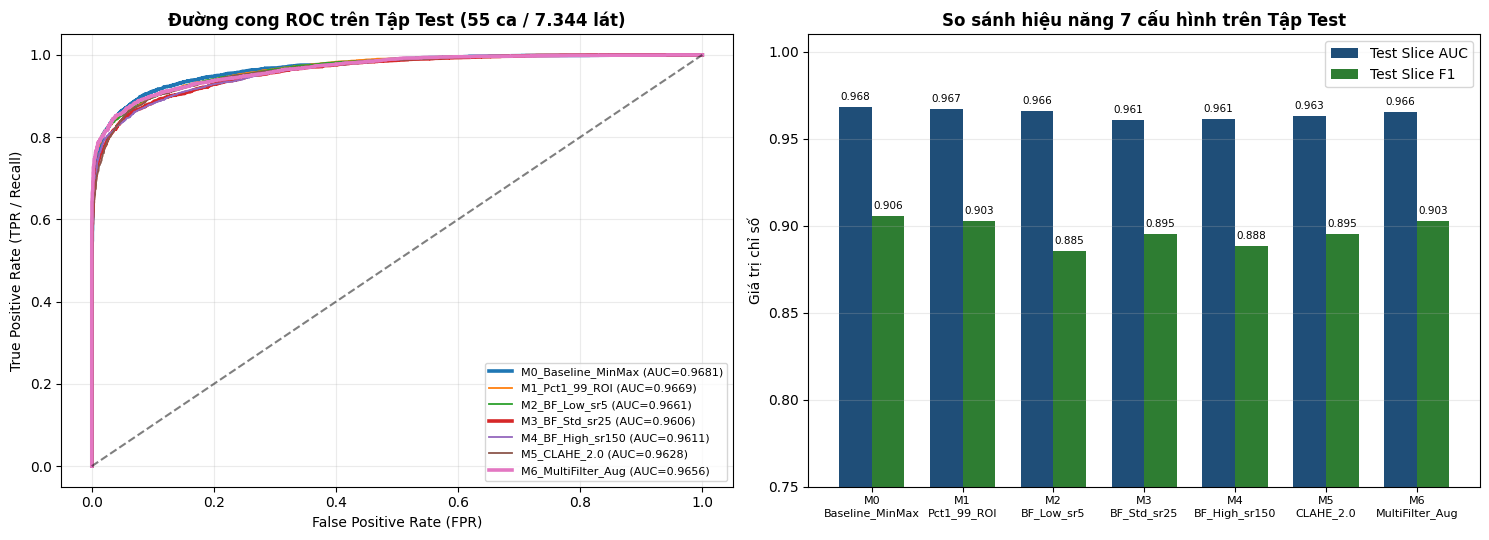

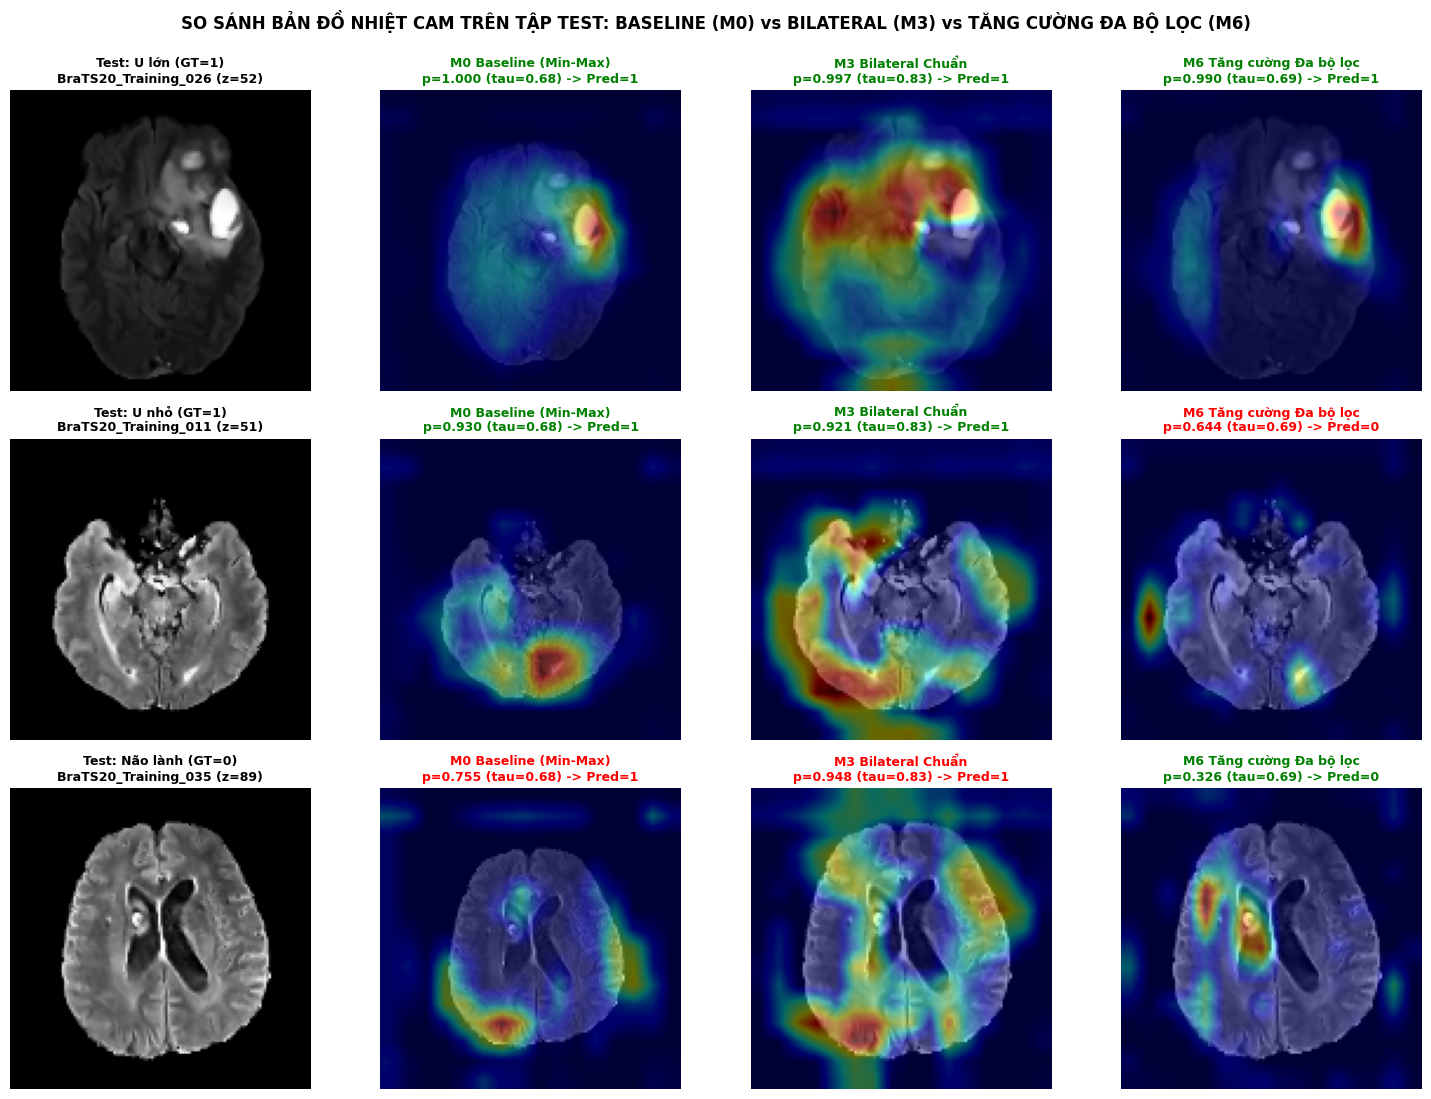


[HOÀN TẤT Ô 5] Toàn bộ kết quả Module 4 đã lưu tại: /content/drive/MyDrive/MRI_Colab_Results_3Splits/module4_experiments


In [7]:
# ==============================================================================
# Ô 5: MODULE 4 (PHẦN 2) — TRAIN CNN ĐA THAM SỐ, TĂNG CƯỜNG ĐA BỘ LỌC & TEST
# ==============================================================================
import os
import time
import random
import gc
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, roc_curve

# 1. Thiết lập môi trường & kiểm tra cache từ Ô 4
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị huấn luyện: {str(device).upper()}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

drive_out = "/content/drive/MyDrive/MRI_Colab_Results_3Splits"
m4_out_dir = os.path.join(drive_out, "module4_experiments")
cache_dir = "/content/m4_cache"
os.makedirs(m4_out_dir, exist_ok=True)

meta_path = os.path.join(cache_dir, "meta_valid_slices.csv")
assert os.path.exists(meta_path), "Không tìm thấy cache Ô 4! Hãy chạy lại Ô 4 trước khi chạy Ô 5."

df_meta = pd.read_csv(meta_path)
N_SLICES = len(df_meta)

VARIANTS = [
    "P0_Baseline_MinMax",
    "P1_Pct1_99_ROI",
    "P2_BF_Low_sr5",
    "P3_BF_Std_sr25",
    "P4_BF_High_sr150",
    "P5_CLAHE_2.0",
]

# Mở các tệp cache ở chế độ chỉ đọc (tiết kiệm RAM)
mmaps = {
    name: np.memmap(os.path.join(cache_dir, f"{name}.dat"), dtype=np.uint8, mode="r", shape=(N_SLICES, 128, 128))
    for name in VARIANTS
}

train_df = df_meta[df_meta["split"] == "train"].reset_index(drop=True)
val_df   = df_meta[df_meta["split"] == "validation"].reset_index(drop=True)
test_df  = df_meta[df_meta["split"] == "test"].reset_index(drop=True)

print(f"Số lát hợp lệ -> Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# 2. Định nghĩa Dataset (hỗ trợ cả đơn tham số và gộp đa bộ lọc + lật ngang tăng cường)
class MultiFilterSliceDataset(Dataset):
    def __init__(self, row_indices, labels, variant_names, augment_flip=False):
        self.row_indices = np.asarray(row_indices, dtype=np.int64)
        self.labels = np.asarray(labels, dtype=np.float32)
        self.variant_names = list(variant_names)
        self.augment_flip = augment_flip
        self.n_base = len(self.row_indices)

    def __len__(self):
        return self.n_base * len(self.variant_names)

    def __getitem__(self, i):
        v_idx = i // self.n_base
        s_idx = i % self.n_base
        r_idx = self.row_indices[s_idx]
        img = mmaps[self.variant_names[v_idx]][r_idx].astype(np.float32) / 255.0
        if self.augment_flip and random.random() < 0.5:
            img = np.ascontiguousarray(img[:, ::-1])
        return torch.from_numpy(img).unsqueeze(0), torch.tensor(self.labels[s_idx], dtype=torch.float32)

# 3. Kiến trúc mạng CNN 2D (4 khối Conv-BN-ReLU + GAP + Linear, hỗ trợ trích xuất CAM)
class SliceClassifierCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(inplace=True), nn.MaxPool2d(2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2)
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True)
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, 1)

    def forward(self, x, return_feat=False):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        feat = self.block4(x)  # (B, 128, 16, 16)
        pooled = self.gap(feat).flatten(1)
        logit = self.fc(pooled).squeeze(1)
        if return_feat:
            return logit, feat
        return logit

# 4. Các hàm dự đoán, tìm ngưỡng trên Validation và chấm điểm trên Test
@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    probs, ys = [], []
    t0 = time.perf_counter()
    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
            logits = model(xb)
            p = torch.sigmoid(logits)
        probs.append(p.float().cpu().numpy())
        ys.append(yb.numpy())
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    probs = np.concatenate(probs)
    ys = np.concatenate(ys).astype(np.int32)
    ms_per_slice = elapsed_ms / max(len(ys), 1)
    return probs, ys, ms_per_slice

def find_best_threshold(y_true, y_prob):
    best_t, best_f1 = 0.50, -1.0
    for t in np.arange(0.15, 0.86, 0.01):
        f1 = f1_score(y_true, (y_prob >= t).astype(np.int32), zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, float(t)
    return round(best_t, 2), float(best_f1)

def compute_all_metrics(df_split, y_prob, tau):
    y_true = df_split["label"].values.astype(np.int32)
    y_pred = (y_prob >= tau).astype(np.int32)
    auc = float(roc_auc_score(y_true, y_prob))
    f1 = float(f1_score(y_true, y_pred, zero_division=0))
    prec = float(precision_score(y_true, y_pred, zero_division=0))
    rec = float(recall_score(y_true, y_pred, zero_division=0))

    # Patient-level Macro F1 / Precision / Recall (trung bình trên từng bệnh nhân)
    tmp = pd.DataFrame({"pid": df_split["patient_id"].values, "y": y_true, "p": y_pred})
    p_f1s, p_precs, p_recs = [], [], []
    for _, g in tmp.groupby("pid"):
        p_f1s.append(f1_score(g["y"], g["p"], zero_division=0))
        p_precs.append(precision_score(g["y"], g["p"], zero_division=0))
        p_recs.append(recall_score(g["y"], g["p"], zero_division=0))

    return {
        "Slice_AUC": round(auc, 4),
        "Slice_F1": round(f1, 4),
        "Slice_Prec": round(prec, 4),
        "Slice_Rec": round(rec, 4),
        "Patient_Macro_F1": round(float(np.mean(p_f1s)), 4),
        "Patient_Macro_Prec": round(float(np.mean(p_precs)), 4),
        "Patient_Macro_Rec": round(float(np.mean(p_recs)), 4),
    }

def train_one_experiment(exp_name, train_variants, eval_variant, epochs=8, batch_size=128, augment_flip=False, save_ckpt=False):
    seed_everything(42)
    ds_train = MultiFilterSliceDataset(train_df["row_idx"].values, train_df["label"].values, train_variants, augment_flip=augment_flip)
    ds_val   = MultiFilterSliceDataset(val_df["row_idx"].values,   val_df["label"].values,   [eval_variant], augment_flip=False)
    ds_test  = MultiFilterSliceDataset(test_df["row_idx"].values,  test_df["label"].values,  [eval_variant], augment_flip=False)

    dl_train = DataLoader(ds_train, batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True)
    dl_val   = DataLoader(ds_val,   batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    dl_test  = DataLoader(ds_test,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

    n_pos = int((train_df["label"] == 1).sum())
    n_neg = int((train_df["label"] == 0).sum())
    pos_weight = torch.tensor([n_neg / max(n_pos, 1)], dtype=torch.float32, device=device)

    model = SliceClassifierCNN().to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))

    best_val_auc = -1.0
    best_state = None
    t_train_start = time.time()

    print(f"\n>>> [{exp_name}] Train={train_variants} ({len(ds_train):,} lát) | Eval={eval_variant} | Epochs={epochs}")
    for ep in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        for xb, yb in dl_train:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                logits = model(xb)
                loss = criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            running_loss += float(loss.item()) * len(yb)

        val_probs, val_ys, _ = predict_probs(model, dl_val)
        val_auc = float(roc_auc_score(val_ys, val_probs))
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"    Epoch {ep}/{epochs} | Train Loss: {running_loss/len(ds_train):.4f} | Val AUC: {val_auc:.4f}")

    train_sec = time.time() - t_train_start
    model.load_state_dict(best_state)

    if save_ckpt:
        torch.save(best_state, os.path.join(m4_out_dir, f"{exp_name}_best.pt"))

    # Quét ngưỡng tối ưu tau* CHỈ trên tập Validation
    val_probs, val_ys, _ = predict_probs(model, dl_val)
    tau_star, _ = find_best_threshold(val_ys, val_probs)
    val_metrics = compute_all_metrics(val_df, val_probs, tau_star)

    # Khóa ngưỡng tau* và chấm điểm độc lập trên tập Test
    test_probs, test_ys, inf_ms = predict_probs(model, dl_test)
    test_metrics = compute_all_metrics(test_df, test_probs, tau_star)

    print(f"    [DONE {exp_name}] tau*={tau_star} | Val AUC={val_metrics['Slice_AUC']} F1={val_metrics['Slice_F1']} "
          f"| TEST AUC={test_metrics['Slice_AUC']} F1={test_metrics['Slice_F1']} (Time: {train_sec:.1f}s)")

    return {
        "exp_name": exp_name,
        "train_variants": "+".join(train_variants),
        "train_slices": len(ds_train),
        "eval_variant": eval_variant,
        "tau_star": tau_star,
        "train_sec": round(train_sec, 1),
        "inf_ms_per_slice": round(inf_ms, 3),
        "val_metrics": val_metrics,
        "test_metrics": test_metrics,
        "test_probs": test_probs,
        "test_ys": test_ys,
        "model": model if save_ckpt else None,
    }

# ==============================================================================
# 5. CHẠY THỰC NGHIỆM 7 CẤU HÌNH (6 ĐƠN THAM SỐ + 1 GỘP ĐA BỘ LỌC TĂNG CƯỜNG)
# ==============================================================================
EXPERIMENTS = [
    ("M0_Baseline_MinMax", ["P0_Baseline_MinMax"], "P0_Baseline_MinMax", 8, False, True),
    ("M1_Pct1_99_ROI",     ["P1_Pct1_99_ROI"],     "P1_Pct1_99_ROI",     8, False, False),
    ("M2_BF_Low_sr5",      ["P2_BF_Low_sr5"],      "P2_BF_Low_sr5",      8, False, False),
    ("M3_BF_Std_sr25",     ["P3_BF_Std_sr25"],     "P3_BF_Std_sr25",     8, False, True),
    ("M4_BF_High_sr150",   ["P4_BF_High_sr150"],   "P4_BF_High_sr150",   8, False, False),
    ("M5_CLAHE_2.0",       ["P5_CLAHE_2.0"],       "P5_CLAHE_2.0",       8, False, False),
    ("M6_MultiFilter_Aug", ["P1_Pct1_99_ROI", "P3_BF_Std_sr25", "P5_CLAHE_2.0"], "P3_BF_Std_sr25", 6, True, True),
]

results = []
saved_models = {}
roc_store = {}

for exp_name, tr_vars, ev_var, eps, aug_flip, keep_model in EXPERIMENTS:
    res = train_one_experiment(exp_name, tr_vars, ev_var, epochs=eps, batch_size=128, augment_flip=aug_flip, save_ckpt=keep_model)
    results.append(res)
    roc_store[exp_name] = (res["test_ys"], res["test_probs"], res["test_metrics"]["Slice_AUC"])
    if keep_model:
        saved_models[exp_name] = (res["model"], res["tau_star"])
    torch.cuda.empty_cache()

# Tổng hợp bảng kết quả 7 cấu hình trên Validation và Test
table_rows = []
for r in results:
    table_rows.append({
        "Mo_hinh": r["exp_name"],
        "So_lat_Train": r["train_slices"],
        "Tap_Test_dau_vao": r["eval_variant"],
        "Tau_Val": r["tau_star"],
        "Val_AUC": r["val_metrics"]["Slice_AUC"],
        "Val_F1": r["val_metrics"]["Slice_F1"],
        "Test_AUC": r["test_metrics"]["Slice_AUC"],
        "Test_F1": r["test_metrics"]["Slice_F1"],
        "Test_Prec": r["test_metrics"]["Slice_Prec"],
        "Test_Rec": r["test_metrics"]["Slice_Rec"],
        "Test_Patient_MacroF1": r["test_metrics"]["Patient_Macro_F1"],
        "Inf_ms": r["inf_ms_per_slice"],
    })
df_results = pd.DataFrame(table_rows)
df_results.to_csv(os.path.join(m4_out_dir, "Module4_7Models_TestResults.csv"), index=False)

print("\n" + "=" * 95)
print("BẢNG 1: ĐỐI CHỨNG 7 CẤU HÌNH CNN TRÊN CÙNG TẬP TEST CỐ ĐỊNH (55 BỆNH NHÂN / 7.344 LÁT)")
print("=" * 95)
print(df_results.to_string(index=False))

# ==============================================================================
# 6. KIỂM CHỨNG ĐỘ NHẠY CHÉO TRÊN TẬP TEST (ĐỔI THAM SỐ BỘ LỌC TRÊN TẬP TEST)
#    So sánh M3 (học 1 bộ lọc) vs M6 (học gộp tăng cường đa bộ lọc)
# ==============================================================================
cross_rows = []
roi_variants_test = ["P1_Pct1_99_ROI", "P2_BF_Low_sr5", "P3_BF_Std_sr25", "P4_BF_High_sr150", "P5_CLAHE_2.0"]

for m_name in ["M3_BF_Std_sr25", "M6_MultiFilter_Aug"]:
    mdl, tau_m = saved_models[m_name]
    for tv in roi_variants_test:
        ds_t = MultiFilterSliceDataset(test_df["row_idx"].values, test_df["label"].values, [tv], augment_flip=False)
        dl_t = DataLoader(ds_t, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)
        probs_t, _, _ = predict_probs(mdl, dl_t)
        met = compute_all_metrics(test_df, probs_t, tau_m)
        cross_rows.append({
            "Mo_hinh_da_train": m_name,
            "Tham_so_loc_Tap_Test": tv,
            "Tau_khoa": tau_m,
            "Test_AUC": met["Slice_AUC"],
            "Test_F1": met["Slice_F1"],
            "Test_Prec": met["Slice_Prec"],
            "Test_Rec": met["Slice_Rec"],
            "Patient_MacroF1": met["Patient_Macro_F1"],
        })

df_cross = pd.DataFrame(cross_rows)
df_cross.to_csv(os.path.join(m4_out_dir, "Module4_CrossFilter_TestRobustness.csv"), index=False)

print("\n" + "=" * 95)
print("BẢNG 2: ĐỘ NHẠY ĐẦU RA KHI ĐỔI THAM SỐ BỘ LỌC TRÊN TẬP TEST (M3 ĐƠN LỌC vs M6 ĐA BỘ LỌC)")
print("=" * 95)
print(df_cross.to_string(index=False))

# Tính độ dao động (Max - Min) của Test F1 để chứng minh độ ổn định
summary_lines = [
    "=== TỔNG HỢP KẾT QUẢ MODULE 4 (3 TẬP: TRAIN 258 / VAL 55 / TEST 55) ===\n",
    "--- BẢNG 1: SO SÁNH 7 CẤU HÌNH CNN ---\n",
    df_results.to_string(index=False),
    "\n\n--- BẢNG 2: ĐỘ NHẠY KHI ĐỔI THAM SỐ BỘ LỌC TRÊN TẬP TEST ---\n",
    df_cross.to_string(index=False),
    "\n\n--- PHÂN TÍCH ĐỘ ỔN ĐỊNH TRÊN TẬP TEST (MAX - MIN F1 QUA 5 BỘ LỌC) ---"
]
for m_name in ["M3_BF_Std_sr25", "M6_MultiFilter_Aug"]:
    sub = df_cross[df_cross["Mo_hinh_da_train"] == m_name]
    f1_span = sub["Test_F1"].max() - sub["Test_F1"].min()
    auc_span = sub["Test_AUC"].max() - sub["Test_AUC"].min()
    line = (f"{m_name}: Test F1 TB = {sub['Test_F1'].mean():.4f} (dao động {f1_span:.4f}) | "
            f"Test AUC TB = {sub['Test_AUC'].mean():.4f} (dao động {auc_span:.4f})")
    print("->", line)
    summary_lines.append(line)

with open(os.path.join(m4_out_dir, "Module4_Summary_Report.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(summary_lines) + "\n")

# ==============================================================================
# 7. VẼ BIỂU ĐỒ ĐỐI CHỨNG ROC & BAR CHART 7 MÔ HÌNH TRÊN TẬP TEST
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Trái: Đường cong ROC trên Tập Test
for exp_name, (ys, ps, auc_v) in roc_store.items():
    fpr, tpr, _ = roc_curve(ys, ps)
    lw = 2.6 if exp_name in ("M0_Baseline_MinMax", "M3_BF_Std_sr25", "M6_MultiFilter_Aug") else 1.3
    axes[0].plot(fpr, tpr, linewidth=lw, label=f"{exp_name} (AUC={auc_v:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("Đường cong ROC trên Tập Test (55 ca / 7.344 lát)", fontweight="bold")
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (TPR / Recall)")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].grid(alpha=0.25)

# Phải: Biểu đồ cột so sánh Test AUC và Test F1
x = np.arange(len(df_results))
w = 0.36
axes[1].bar(x - w/2, df_results["Test_AUC"], w, label="Test Slice AUC", color="#1f4e78")
axes[1].bar(x + w/2, df_results["Test_F1"],  w, label="Test Slice F1",  color="#2e7d32")
axes[1].set_xticks(x)
axes[1].set_xticklabels([n.replace("_", "\n", 1) for n in df_results["Mo_hinh"]], fontsize=8)
axes[1].set_ylim(0.75, 1.01)
axes[1].set_ylabel("Giá trị chỉ số")
axes[1].set_title("So sánh hiệu năng 7 cấu hình trên Tập Test", fontweight="bold")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)
for i, r in df_results.iterrows():
    axes[1].text(i - w/2, r["Test_AUC"] + 0.004, f"{r['Test_AUC']:.3f}", ha="center", fontsize=7.5)
    axes[1].text(i + w/2, r["Test_F1"]  + 0.004, f"{r['Test_F1']:.3f}",  ha="center", fontsize=7.5)

plt.tight_layout()
plt.savefig(os.path.join(m4_out_dir, "Module4_ROC_and_F1_Comparison.png"), dpi=220, bbox_inches="tight")
plt.show()

# ==============================================================================
# 8. TRỰC QUAN HÓA BẢN ĐỒ NHIỆT CAM TRÊN 3 MẪU TẬP TEST (M0 vs M3 vs M6)
# ==============================================================================
@torch.no_grad()
def get_cam_and_prob(model, img_u8):
    model.eval()
    x_t = torch.from_numpy(img_u8.astype(np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(device)
    logit, feat = model(x_t, return_feat=True)
    prob = float(torch.sigmoid(logit).item())
    weights = model.fc.weight.squeeze(0)  # (128,)
    cam = torch.relu((weights[:, None, None] * feat.squeeze(0)).sum(dim=0)).cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    cam = cv2.resize(cam, (128, 128), interpolation=cv2.INTER_LINEAR)
    return prob, cam

# Chọn 3 lát đại diện từ Tập TEST: 1 u lớn, 1 u nhỏ, 1 lát não lành giữa não
test_pos_large = test_df[test_df["wt_pixels"] > 2500].iloc[0]
test_pos_small = test_df[(test_df["wt_pixels"] > 200) & (test_df["wt_pixels"] < 900)].iloc[0]
test_neg_mid   = test_df[(test_df["label"] == 0) & (test_df["slice_index"].between(65, 95)) & (test_df["brain_pixels"] > 12000)].iloc[0]

cam_samples = [
    (test_pos_large, "Test: U lớn (GT=1)"),
    (test_pos_small, "Test: U nhỏ (GT=1)"),
    (test_neg_mid,   "Test: Não lành (GT=0)"),
]

fig, axes = plt.subplots(3, 4, figsize=(15, 11))
fig.suptitle("SO SÁNH BẢN ĐỒ NHIỆT CAM TRÊN TẬP TEST: BASELINE (M0) vs BILATERAL (M3) vs TĂNG CƯỜNG ĐA BỘ LỌC (M6)", fontweight="bold", y=0.995)

m0_mdl, m0_tau = saved_models["M0_Baseline_MinMax"]
m3_mdl, m3_tau = saved_models["M3_BF_Std_sr25"]
m6_mdl, m6_tau = saved_models["M6_MultiFilter_Aug"]

for r_i, (row_s, label_txt) in enumerate(cam_samples):
    ridx = int(row_s["row_idx"])
    img_p0 = mmaps["P0_Baseline_MinMax"][ridx]
    img_p3 = mmaps["P3_BF_Std_sr25"][ridx]

    p0, cam0 = get_cam_and_prob(m0_mdl, img_p0)
    p3, cam3 = get_cam_and_prob(m3_mdl, img_p3)
    p6, cam6 = get_cam_and_prob(m6_mdl, img_p3)

    axes[r_i, 0].imshow(np.rot90(img_p3), cmap="gray")
    axes[r_i, 0].set_title(f"{label_txt}\n{row_s['patient_id']} (z={row_s['slice_index']})", fontsize=9, fontweight="bold")
    axes[r_i, 0].axis("off")

    for c_i, (base_im, cam_im, p_val, tau_v, title_m) in enumerate([
        (img_p0, cam0, p0, m0_tau, "M0 Baseline (Min-Max)"),
        (img_p3, cam3, p3, m3_tau, "M3 Bilateral Chuẩn"),
        (img_p3, cam6, p6, m6_tau, "M6 Tăng cường Đa bộ lọc"),
    ], start=1):
        pred = int(p_val >= tau_v)
        axes[r_i, c_i].imshow(np.rot90(base_im), cmap="gray")
        axes[r_i, c_i].imshow(np.rot90(cam_im), cmap="jet", alpha=0.42)
        color_t = "green" if pred == int(row_s["label"]) else "red"
        axes[r_i, c_i].set_title(f"{title_m}\np={p_val:.3f} (tau={tau_v}) -> Pred={pred}", fontsize=9, color=color_t, fontweight="bold")
        axes[r_i, c_i].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(m4_out_dir, "Module4_CAM_TestSamples_Comparison.png"), dpi=220, bbox_inches="tight")
plt.show()

gc.collect()
print(f"\n[HOÀN TẤT Ô 5] Toàn bộ kết quả Module 4 đã lưu tại: {m4_out_dir}")